<a href="https://colab.research.google.com/github/Shamanthking/Audio-Speech-To-Sign-Language-Converter/blob/main/Chair_Revision_Corrected_Experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 1. Install required packages and download dataset
!pip install -q ctgan xgboost shap lime openpyxl
!gdown -O /content/Disease_dataset_reduced_50k.csv "https://drive.google.com/uc?export=download&id=1d9yxG8atH2_n-77zNXqe-apZLdFj-7HK"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Downloading...
From: https://drive.google.com/uc?export=download&id=1d9yxG8atH2_n-77zNXqe-apZLdFj-7HK
To: /content/Disease_dataset_reduced_50k.csv
100% 38.9M/38.9M [00:00<00:00, 53.7MB/s]


In [ ]:
# 2. Import all libraries and set up configurations
import os
import random
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from ctgan import CTGAN
import xgboost as xgb

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import VarianceThreshold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, top_k_accuracy_score
)
import shap
from lime.lime_tabular import LimeTabularExplainer

RANDOM_STATE = 42
TOP_N = 100
TEST_SIZE = 0.20
CTGAN_EPOCHS = 5
MLP_EPOCHS = 30
MLP_HIDDEN = 256
LEARNING_RATE = 0.001
RF_ESTIMATORS = 500
XGB_ESTIMATORS = 500
XGB_MAX_DEPTH = 6
XGB_LEARNING_RATE = 0.05

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cpu


In [ ]:
# 1. Data Loading & Cleaning
df = pd.read_csv('/content/Disease_dataset_reduced_50k.csv')
TARGET_COLUMN = 'diseases'
df = df.drop_duplicates()
df = df.fillna(0)

# Filter to Top 100 Diseases
disease_counts = df[TARGET_COLUMN].value_counts()
top_diseases = disease_counts.nlargest(TOP_N).index
df_top = df[df[TARGET_COLUMN].isin(top_diseases)].reset_index(drop=True)

# Feature extraction
feature_columns_original = [c for c in df_top.columns if c != TARGET_COLUMN]
X_original = df_top[feature_columns_original].apply(pd.to_numeric, errors='coerce').fillna(0)
y_text = df_top[TARGET_COLUMN].astype(str)

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_text)
class_names = label_encoder.classes_
num_classes = len(class_names)

# Variance threshold
variance_selector = VarianceThreshold(threshold=0.0)
X_selected = variance_selector.fit_transform(X_original)
support_mask = variance_selector.get_support()
feature_columns = [feature_columns_original[i] for i in range(len(feature_columns_original)) if support_mask[i]]
X = pd.DataFrame(X_selected, columns=feature_columns).astype(float)

print('Data Preparation Completed:', X.shape)

Data Preparation Completed: (25287, 229)


In [ ]:
# 2. Train Test Split FIRST
X_train_real, X_test, y_train_real, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
X_train_real = X_train_real.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train_real = np.asarray(y_train_real)
y_test = np.asarray(y_test)
print('Train/Test Split Completed!')

Train/Test Split Completed!


In [ ]:
# Helper functions and definitions for model training and evaluation

def augment_with_ctgan(X_train, y_train, target_count=None, epochs=5):
    X_train = X_train.copy().reset_index(drop=True)
    y_train = np.asarray(y_train)
    ctgan_data = X_train.copy()
    ctgan_data['disease_label'] = y_train.astype(str)
    class_counts = pd.Series(y_train).value_counts().sort_index()
    if target_count is None:
        target_count = int(class_counts.median())

    discrete_columns = list(X_train.columns) + ['disease_label']
    ctgan = CTGAN(epochs=epochs, verbose=False)
    print('Training CTGAN...')
    ctgan.fit(ctgan_data, discrete_columns=discrete_columns)

    X_parts = [X_train.values]
    y_parts = [y_train]

    minority_classes = class_counts[class_counts < target_count].index.tolist()
    for class_id in minority_classes:
        current_count = int(class_counts[class_id])
        required = target_count - current_count
        if required <= 0:
            continue
        try:
            synthetic = ctgan.sample(required, condition_column='disease_label', condition_value=str(class_id))
        except Exception:
            pool = ctgan.sample(max(required * 30, 1000))
            synthetic = pool[pool['disease_label'].astype(str) == str(class_id)].head(required)

        if len(synthetic) == 0:
            continue
        synthetic_X = synthetic[X_train.columns].copy().apply(pd.to_numeric, errors='coerce').fillna(0)
        synthetic_X = synthetic_X.round().clip(0, 1)
        X_parts.append(synthetic_X.values)
        y_parts.append(np.full(len(synthetic_X), class_id, dtype=int))

    X_augmented = pd.DataFrame(np.concatenate(X_parts, axis=0), columns=X_train.columns)
    y_augmented = np.concatenate(y_parts, axis=0)
    return X_augmented, y_augmented, ctgan

class MLPResNet(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.bn1 = nn.BatchNorm1d(hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.bn2 = nn.BatchNorm1d(hidden_dim)
        self.fc3 = nn.Linear(hidden_dim, output_dim)
    def forward(self, x):
        out = F.relu(self.bn1(self.fc1(x)))
        residual = out
        out = F.relu(self.bn2(self.fc2(out)))
        out = self.fc3(out + residual)
        return out

def train_mlp_resnet(X_train, y_train):
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_train)
    X_tensor = torch.tensor(X_scaled, dtype=torch.float32).to(device)
    y_tensor = torch.tensor(y_train, dtype=torch.long).to(device)
    model = MLPResNet(input_dim=X_train.shape[1], hidden_dim=MLP_HIDDEN, output_dim=num_classes).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    criterion = nn.CrossEntropyLoss()
    model.train()
    for epoch in range(MLP_EPOCHS):
        optimizer.zero_grad()
        outputs = model(X_tensor)
        loss = criterion(outputs, y_tensor)
        loss.backward()
        optimizer.step()
    return model, scaler

def train_xgboost(X_train, y_train):
    model = xgb.XGBClassifier(objective='multi:softprob', num_class=num_classes, eval_metric='mlogloss', n_estimators=XGB_ESTIMATORS, max_depth=XGB_MAX_DEPTH, learning_rate=XGB_LEARNING_RATE, subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=-1, tree_method='hist')
    model.fit(X_train, y_train)
    return model

def train_random_forest(X_train, y_train):
    model = RandomForestClassifier(n_estimators=RF_ESTIMATORS, random_state=RANDOM_STATE, n_jobs=-1)
    model.fit(X_train, y_train)
    return model

def train_experiment(use_ctgan=False):
    if use_ctgan:
        print('EXPERIMENT: WITH CTGAN')
        X_train, y_train, ctgan_model = augment_with_ctgan(X_train_real, y_train_real, target_count=None, epochs=CTGAN_EPOCHS)
    else:
        print('EXPERIMENT: WITHOUT CTGAN')
        X_train, y_train, ctgan_model = X_train_real.copy(), y_train_real.copy(), None
    print('Training MLP + ResNet...')
    mlp_model, scaler = train_mlp_resnet(X_train, y_train)
    print('Training XGBoost...')
    xgb_model = train_xgboost(X_train, y_train)
    print('Training Random Forest...')
    rf_model = train_random_forest(X_train, y_train)
    return {'X_train': X_train, 'y_train': y_train, 'mlp': mlp_model, 'scaler': scaler, 'xgb': xgb_model, 'rf': rf_model, 'ctgan': ctgan_model}

def predict_models(experiment):
    scaler, mlp_model = experiment['scaler'], experiment['mlp']
    X_test_scaled = scaler.transform(X_test)
    X_tensor = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)
    mlp_model.eval()
    with torch.no_grad():
        mlp_probs = F.softmax(mlp_model(X_tensor), dim=1).cpu().numpy()
    xgb_probs = experiment['xgb'].predict_proba(X_test)
    rf_probs = experiment['rf'].predict_proba(X_test)
    ensemble_probs = (mlp_probs + xgb_probs + rf_probs) / 3.0
    return {
        'MLP + ResNet': {'pred': np.argmax(mlp_probs, axis=1), 'prob': mlp_probs},
        'XGBoost': {'pred': np.argmax(xgb_probs, axis=1), 'prob': xgb_probs},
        'Random Forest': {'pred': np.argmax(rf_probs, axis=1), 'prob': rf_probs},
        'Soft Voting Ensemble': {'pred': np.argmax(ensemble_probs, axis=1), 'prob': ensemble_probs}
    }

def calculate_metrics(y_true, predictions):
    results = []
    for model_name, output in predictions.items():
        pred, probs = output['pred'], output['prob']
        results.append({
            'Model': model_name,
            'Accuracy (%)': accuracy_score(y_true, pred) * 100,
            'Macro Precision (%)': precision_score(y_true, pred, average='macro', zero_division=0) * 100,
            'Macro Recall (%)': recall_score(y_true, pred, average='macro', zero_division=0) * 100,
            'Macro F1-score (%)': f1_score(y_true, pred, average='macro', zero_division=0) * 100,
            'Top-3 Accuracy (%)': top_k_accuracy_score(y_true, probs, k=3, labels=np.arange(num_classes)) * 100
        })
    return pd.DataFrame(results)

In [ ]:
# 3. Run Experiments (Without and With CTGAN applied strictly on Train data)
experiment_without_ctgan = train_experiment(use_ctgan=False)
predictions_without_ctgan = predict_models(experiment_without_ctgan)
results_without_ctgan = calculate_metrics(y_test, predictions_without_ctgan)

print('--- RESULTS WITHOUT CTGAN ---')
display(results_without_ctgan.round(4))

experiment_with_ctgan = train_experiment(use_ctgan=True)
predictions_with_ctgan = predict_models(experiment_with_ctgan)
results_with_ctgan = calculate_metrics(y_test, predictions_with_ctgan)

print('--- RESULTS WITH CTGAN ---')
display(results_with_ctgan.round(4))

print('Experiments completed successfully in the correct sequence!')

EXPERIMENT: WITHOUT CTGAN
Training MLP + ResNet...
Training XGBoost...
Training Random Forest...
--- RESULTS WITHOUT CTGAN ---


,Model,Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1-score (%),Top-3 Accuracy (%)
0,MLP + ResNet,86.1012,87.4216,85.5992,85.9367,97.8252
1,XGBoost,87.4456,87.7316,87.3020,87.3871,98.2009
2,Random Forest,87.6829,87.9152,87.5306,87.5538,98.1416
3,Soft Voting Ensemble,87.7817,88.0953,87.6229,87.7252,98.3393


EXPERIMENT: WITH CTGAN
Training CTGAN...
Training MLP + ResNet...
Training XGBoost...
Training Random Forest...
--- RESULTS WITH CTGAN ---


,Model,Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1-score (%),Top-3 Accuracy (%)
0,MLP + ResNet,86.4373,88.1573,85.8309,86.2251,97.7264
1,XGBoost,87.6236,87.7990,87.5146,87.5403,98.1613
2,Random Forest,87.8806,88.1020,87.7095,87.7589,98.3393
3,Soft Voting Ensemble,87.6829,88.0126,87.5320,87.6507,98.3986


Experiments completed successfully in the correct sequence!


In [ ]:
!pip -q install ctgan xgboost shap lime openpyxl

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 6.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.5/75.5 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 47.4 MB/s eta 0:00:00


In [ ]:
import os
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F

from ctgan import CTGAN
import xgboost as xgb

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import VarianceThreshold

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    top_k_accuracy_score
)

import shap
from lime.lime_tabular import LimeTabularExplainer

RANDOM_STATE = 42

TOP_N = 100
TEST_SIZE = 0.20

CTGAN_EPOCHS = 5

MLP_EPOCHS = 30
MLP_HIDDEN = 256
LEARNING_RATE = 0.001

RF_ESTIMATORS = 500

XGB_ESTIMATORS = 500
XGB_MAX_DEPTH = 6
XGB_LEARNING_RATE = 0.05

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cpu


In [ ]:

df = pd.read_csv("/content/Disease_dataset_reduced_50k.csv")

print("Original dataset shape:")
print(df.shape)

display(df.head())

Original dataset shape:
(50399, 378)


,diseases,anxiety and nervousness,depression,shortness of breath,depressive or psychotic symptoms,sharp chest pain,dizziness,insomnia,abnormal involuntary movements,chest tightness,...,stuttering or stammering,problems with orgasm,nose deformity,lump over jaw,sore in nose,hip weakness,back swelling,ankle stiffness or tightness,ankle weakness,neck weakness
0,spontaneous abortion,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,peripheral nerve disorder,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,chronic back pain,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,bladder disorder,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,fungal infection of the hair,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
TARGET_COLUMN = "diseases"

if TARGET_COLUMN not in df.columns:
    raise ValueError(
        f"Target column '{TARGET_COLUMN}' not found."
    )

print("Target column:", TARGET_COLUMN)

# Remove duplicate records
before = len(df)

df = df.drop_duplicates()

after = len(df)

print(
    "Duplicates removed:",
    before - after
)

# Missing values
df = df.fillna(0)

print(
    "Dataset after cleaning:",
    df.shape
)

Target column: diseases
Duplicates removed: 672
Dataset after cleaning: (49727, 378)


In [ ]:
# Count disease classes

disease_counts = (
    df[TARGET_COLUMN]
    .value_counts()
)

print(
    "Total disease classes:",
    len(disease_counts)
)


# Select top 100

top_diseases = (
    disease_counts
    .nlargest(TOP_N)
    .index
)


df_top = (
    df[
        df[TARGET_COLUMN]
        .isin(top_diseases)
    ]
    .reset_index(drop=True)
)


print(
    "Top-100 dataset shape:",
    df_top.shape
)

print(
    "Number of selected classes:",
    df_top[TARGET_COLUMN].nunique()
)

Total disease classes: 773
Top-100 dataset shape: (25287, 378)
Number of selected classes: 100


In [ ]:
feature_columns_original = [
    column
    for column in df_top.columns
    if column != TARGET_COLUMN
]

X_original = (
    df_top[
        feature_columns_original
    ]
    .apply(
        pd.to_numeric,
        errors="coerce"
    )
    .fillna(0)
)

y_text = (
    df_top[TARGET_COLUMN]
    .astype(str)
)

print(
    "Original feature count:",
    X_original.shape[1]
)

print(
    "Samples:",
    X_original.shape[0]
)

Original feature count: 377
Samples: 25287


In [ ]:
# ============================================================
# LABEL ENCODING
# ============================================================

label_encoder = LabelEncoder()

y = label_encoder.fit_transform(
    y_text
)

class_names = (
    label_encoder.classes_
)

num_classes = (
    len(class_names)
)

print(
    "Number of classes:",
    num_classes
)

print(
    "\nFirst 20 encoded classes:"
)

for i in range(
    min(20, num_classes)
):

    print(
        i,
        "->",
        class_names[i]
    )

Number of classes: 100

First 20 encoded classes:
0 -> actinic keratosis
1 -> acute bronchiolitis
2 -> acute bronchitis
3 -> acute bronchospasm
4 -> acute kidney injury
5 -> acute pancreatitis
6 -> acute sinusitis
7 -> allergy
8 -> angina
9 -> anxiety
10 -> appendicitis
11 -> arthritis of the hip
12 -> asthma
13 -> benign prostatic hyperplasia (bph)
14 -> brachial neuritis
15 -> bursitis
16 -> carpal tunnel syndrome
17 -> cholecystitis
18 -> chronic back pain
19 -> chronic constipation


In [ ]:
variance_selector = (
    VarianceThreshold(
        threshold=0.0
    )
)

X_selected = (
    variance_selector
    .fit_transform(
        X_original
    )
)

support_mask = (
    variance_selector
    .get_support()
)

feature_columns = [
    feature_columns_original[i]
    for i in range(
        len(feature_columns_original)
    )
    if support_mask[i]
]

X = pd.DataFrame(
    X_selected,
    columns=feature_columns
)

X = X.astype(float)

print(
    "Final feature count:",
    X.shape[1]
)

print(
    "Final sample count:",
    X.shape[0]
)

Final feature count: 229
Final sample count: 25287


In [ ]:
X_train_real, X_test, y_train_real, y_test = (
    train_test_split(
        X,
        y,

        test_size=TEST_SIZE,

        random_state=RANDOM_STATE,

        stratify=y
    )
)

X_train_real = (
    X_train_real
    .reset_index(drop=True)
)

X_test = (
    X_test
    .reset_index(drop=True)
)

y_train_real = (
    np.asarray(
        y_train_real
    )
)

y_test = (
    np.asarray(
        y_test
    )
)

print(
    "Training samples:",
    len(X_train_real)
)

print(
    "Testing samples:",
    len(X_test)
)

Training samples: 20229
Testing samples: 5058


In [ ]:
train_counts = (
    pd.Series(
        y_train_real
    )
    .value_counts()
    .sort_index()
)

test_counts = (
    pd.Series(
        y_test
    )
    .value_counts()
    .sort_index()
)

distribution_table = pd.DataFrame({

    "Class ID":
        np.arange(num_classes),

    "Disease":
        class_names,

    "Training Count": [
        train_counts.get(
            i,
            0
        )
        for i in range(
            num_classes
        )
    ],

    "Testing Count": [
        test_counts.get(
            i,
            0
        )
        for i in range(
            num_classes
        )
    ]
})

display(
    distribution_table.head(20)
)

print(
    "Minimum training count:",
    train_counts.min()
)

print(
    "Maximum training count:",
    train_counts.max()
)

,Class ID,Disease,Training Count,Testing Count
0,0,actinic keratosis,170,43
1,1,acute bronchiolitis,254,63
2,2,acute bronchitis,255,64
3,3,acute bronchospasm,171,43
4,4,acute kidney injury,170,43
5,5,acute pancreatitis,254,64
6,6,acute sinusitis,174,44
7,7,allergy,169,42
8,8,angina,174,43
9,9,anxiety,252,63


Minimum training count: 169
Maximum training count: 257


In [ ]:
def augment_with_ctgan(
    X_train,
    y_train,
    target_count=None,
    epochs=5
):

    X_train = (
        X_train
        .copy()
        .reset_index(drop=True)
    )

    y_train = np.asarray(
        y_train
    )

    # Create CTGAN training dataframe

    ctgan_data = (
        X_train.copy()
    )

    ctgan_data[
        "disease_label"
    ] = y_train.astype(str)


    # Class distribution

    class_counts = (
        pd.Series(
            y_train
        )
        .value_counts()
        .sort_index()
    )


    # Median class count as
    # balancing target

    if target_count is None:

        target_count = int(
            class_counts.median()
        )


    print(
        "CTGAN target count:",
        target_count
    )


    # CTGAN

    discrete_columns = (
        list(X_train.columns)
        +
        ["disease_label"]
    )

    ctgan = CTGAN(
        epochs=epochs,
        verbose=True
    )

    print(
        "Training CTGAN..."
    )

    ctgan.fit(
        ctgan_data,
        discrete_columns=
            discrete_columns
    )


    # Start with real training data

    X_parts = [
        X_train.values
    ]

    y_parts = [
        y_train
    ]


    # Minority classes

    minority_classes = (
        class_counts[
            class_counts
            < target_count
        ]
        .index
        .tolist()
    )


    print(
        "Minority classes:",
        len(minority_classes)
    )


    # Generate synthetic samples

    for class_id in (
        minority_classes
    ):

        current_count = int(
            class_counts[
                class_id
            ]
        )

        required = (
            target_count
            -
            current_count
        )


        if required <= 0:
            continue


        print(
            "\nClass:",
            class_names[
                class_id
            ]
        )

        print(
            "Current:",
            current_count
        )

        print(
            "Generating:",
            required
        )


        try:

            synthetic = (
                ctgan.sample(
                    required,
                    condition_column=
                        "disease_label",
                    condition_value=
                        str(class_id)
                )
            )

        except Exception:

            pool_size = max(
                required * 30,
                1000
            )

            pool = (
                ctgan.sample(
                    pool_size
                )
            )

            synthetic = (
                pool[
                    pool[
                        "disease_label"
                    ]
                    .astype(str)
                    ==
                    str(class_id)
                ]
                .head(required)
            )


        if len(synthetic) == 0:

            print(
                "No synthetic samples generated."
            )

            continue


        synthetic_X = (
            synthetic[
                X_train.columns
            ]
            .copy()
        )


        synthetic_X = (
            synthetic_X
            .apply(
                pd.to_numeric,
                errors="coerce"
            )
            .fillna(0)
        )


        # Binary symptom representation

        synthetic_X = (
            synthetic_X
            .round()
            .clip(0, 1)
        )


        X_parts.append(
            synthetic_X.values
        )

        y_parts.append(
            np.full(
                len(synthetic_X),
                class_id,
                dtype=int
            )
        )


    # Combine

    X_augmented = pd.DataFrame(
        np.concatenate(
            X_parts,
            axis=0
        ),

        columns=X_train.columns
    )

    y_augmented = np.concatenate(
        y_parts,
        axis=0
    )


    print(
        "\nTraining samples before CTGAN:",
        len(X_train)
    )

    print(
        "Training samples after CTGAN:",
        len(X_augmented)
    )


    return (
        X_augmented,
        y_augmented,
        ctgan
    )

In [ ]:
class MLPResNet(
    nn.Module
):

    def __init__(
        self,
        input_dim,
        hidden_dim,
        output_dim
    ):

        super().__init__()


        self.fc1 = nn.Linear(
            input_dim,
            hidden_dim
        )

        self.bn1 = nn.BatchNorm1d(
            hidden_dim
        )


        self.fc2 = nn.Linear(
            hidden_dim,
            hidden_dim
        )

        self.bn2 = nn.BatchNorm1d(
            hidden_dim
        )


        self.fc3 = nn.Linear(
            hidden_dim,
            output_dim
        )


    def forward(
        self,
        x
    ):

        out = self.fc1(x)

        out = self.bn1(
            out
        )

        out = F.relu(
            out
        )


        residual = out


        out = self.fc2(
            out
        )

        out = self.bn2(
            out
        )

        out = F.relu(
            out
        )


        out = (
            out
            +
            residual
        )


        out = self.fc3(
            out
        )


        return out

In [ ]:
def train_mlp_resnet(
    X_train,
    y_train
):

    # Scale only for neural network

    scaler = StandardScaler()

    X_scaled = (
        scaler.fit_transform(
            X_train
        )
    )


    X_tensor = torch.tensor(
        X_scaled,
        dtype=torch.float32
    ).to(device)


    y_tensor = torch.tensor(
        y_train,
        dtype=torch.long
    ).to(device)


    model = MLPResNet(

        input_dim=
            X_train.shape[1],

        hidden_dim=
            MLP_HIDDEN,

        output_dim=
            num_classes

    ).to(device)


    optimizer = torch.optim.Adam(
        model.parameters(),

        lr=LEARNING_RATE
    )


    criterion = (
        nn.CrossEntropyLoss()
    )


    model.train()


    for epoch in range(
        MLP_EPOCHS
    ):

        optimizer.zero_grad()


        outputs = model(
            X_tensor
        )


        loss = criterion(
            outputs,
            y_tensor
        )


        loss.backward()


        optimizer.step()


        if (
            epoch == 0
            or
            (epoch + 1) % 5 == 0
        ):

            print(
                f"Epoch "
                f"{epoch + 1}/"
                f"{MLP_EPOCHS} "
                f"Loss: "
                f"{loss.item():.6f}"
            )


    return (
        model,
        scaler
    )

In [ ]:
def train_xgboost(
    X_train,
    y_train
):

    model = xgb.XGBClassifier(

        objective=
            "multi:softprob",

        num_class=
            num_classes,

        eval_metric=
            "mlogloss",

        n_estimators=
            XGB_ESTIMATORS,

        max_depth=
            XGB_MAX_DEPTH,

        learning_rate=
            XGB_LEARNING_RATE,

        subsample=0.8,

        colsample_bytree=0.8,

        random_state=
            RANDOM_STATE,

        n_jobs=-1,

        tree_method="hist"
    )


    model.fit(
        X_train,
        y_train
    )


    return model

In [ ]:
def train_random_forest(
    X_train,
    y_train
):

    model = (
        RandomForestClassifier(

            n_estimators=
                RF_ESTIMATORS,

            random_state=
                RANDOM_STATE,

            n_jobs=-1
        )
    )


    model.fit(
        X_train,
        y_train
    )


    return model

In [ ]:
def train_experiment(
    use_ctgan=False
):

    print(
        "\n"
        +
        "=" * 70
    )


    if use_ctgan:

        print(
            "EXPERIMENT: WITH CTGAN"
        )

    else:

        print(
            "EXPERIMENT: WITHOUT CTGAN"
        )


    print(
        "=" * 70
    )


    # --------------------------------------------------------
    # CTGAN
    # --------------------------------------------------------

    if use_ctgan:

        (
            X_train,
            y_train,
            ctgan_model
        ) = augment_with_ctgan(

            X_train_real,

            y_train_real,

            target_count=None,

            epochs=
                CTGAN_EPOCHS
        )


    else:

        X_train = (
            X_train_real.copy()
        )

        y_train = (
            y_train_real.copy()
        )

        ctgan_model = None


    # --------------------------------------------------------
    # MLP
    # --------------------------------------------------------

    print(
        "\nTraining MLP + ResNet..."
    )


    (
        mlp_model,
        scaler
    ) = train_mlp_resnet(

        X_train,

        y_train
    )


    # --------------------------------------------------------
    # XGBOOST
    # --------------------------------------------------------

    print(
        "\nTraining XGBoost..."
    )


    xgb_model = (
        train_xgboost(
            X_train,
            y_train
        )
    )


    # --------------------------------------------------------
    # RANDOM FOREST
    # --------------------------------------------------------

    print(
        "\nTraining Random Forest..."
    )


    rf_model = (
        train_random_forest(
            X_train,
            y_train
        )
    )


    return {

        "X_train":
            X_train,

        "y_train":
            y_train,

        "mlp":
            mlp_model,

        "scaler":
            scaler,

        "xgb":
            xgb_model,

        "rf":
            rf_model,

        "ctgan":
            ctgan_model
    }

In [ ]:
def predict_models(
    experiment
):

    # ========================================================
    # MLP
    # ========================================================

    scaler = (
        experiment[
            "scaler"
        ]
    )

    mlp_model = (
        experiment[
            "mlp"
        ]
    )


    X_test_scaled = (
        scaler.transform(
            X_test
        )
    )


    X_tensor = torch.tensor(
        X_test_scaled,
        dtype=torch.float32
    ).to(device)


    mlp_model.eval()


    with torch.no_grad():

        mlp_logits = (
            mlp_model(
                X_tensor
            )
        )


        mlp_probs = (
            F.softmax(
                mlp_logits,
                dim=1
            )
            .cpu()
            .numpy()
        )


    # ========================================================
    # XGBOOST
    # UN-SCALED
    # ========================================================

    xgb_probs = (
        experiment[
            "xgb"
        ]
        .predict_proba(
            X_test
        )
    )


    # ========================================================
    # RANDOM FOREST
    # UN-SCALED
    # ========================================================

    rf_probs = (
        experiment[
            "rf"
        ]
        .predict_proba(
            X_test
        )
    )


    # ========================================================
    # SOFT VOTING
    # ========================================================

    ensemble_probs = (
        mlp_probs
        +
        xgb_probs
        +
        rf_probs
    ) / 3.0


    return {

        "MLP + ResNet": {

            "pred":
                np.argmax(
                    mlp_probs,
                    axis=1
                ),

            "prob":
                mlp_probs
        },


        "XGBoost": {

            "pred":
                np.argmax(
                    xgb_probs,
                    axis=1
                ),

            "prob":
                xgb_probs
        },


        "Random Forest": {

            "pred":
                np.argmax(
                    rf_probs,
                    axis=1
                ),

            "prob":
                rf_probs
        },


        "Soft Voting Ensemble": {

            "pred":
                np.argmax(
                    ensemble_probs,
                    axis=1
                ),

            "prob":
                ensemble_probs
        }
    }

In [ ]:
def calculate_metrics(
    y_true,
    predictions
):

    results = []


    for (
        model_name,
        output
    ) in predictions.items():


        pred = output[
            "pred"
        ]

        probs = output[
            "prob"
        ]


        accuracy = (
            accuracy_score(
                y_true,
                pred
            )
        )


        macro_precision = (
            precision_score(
                y_true,
                pred,
                average="macro",
                zero_division=0
            )
        )


        macro_recall = (
            recall_score(
                y_true,
                pred,
                average="macro",
                zero_division=0
            )
        )


        macro_f1 = (
            f1_score(
                y_true,
                pred,
                average="macro",
                zero_division=0
            )
        )


        top3 = (
            top_k_accuracy_score(

                y_true,

                probs,

                k=3,

                labels=np.arange(
                    num_classes
                )
            )
        )


        results.append({

            "Model":
                model_name,

            "Accuracy (%)":
                accuracy * 100,

            "Macro Precision (%)":
                macro_precision * 100,

            "Macro Recall (%)":
                macro_recall * 100,

            "Macro F1-score (%)":
                macro_f1 * 100,

            "Top-3 Accuracy (%)":
                top3 * 100
        })


    return pd.DataFrame(
        results
    )

In [ ]:
experiment_without_ctgan = (
    train_experiment(
        use_ctgan=False
    )
)


predictions_without_ctgan = (
    predict_models(
        experiment_without_ctgan
    )
)


results_without_ctgan = (
    calculate_metrics(

        y_test,

        predictions_without_ctgan
    )
)


print(
    "RESULTS WITHOUT CTGAN"
)

display(
    results_without_ctgan.round(4)
)


EXPERIMENT: WITHOUT CTGAN

Training MLP + ResNet...
Epoch 1/30 Loss: 4.802086
Epoch 5/30 Loss: 3.333049
Epoch 10/30 Loss: 2.165449
Epoch 15/30 Loss: 1.465833
Epoch 20/30 Loss: 1.020904
Epoch 25/30 Loss: 0.741910
Epoch 30/30 Loss: 0.570412

Training XGBoost...

Training Random Forest...
RESULTS WITHOUT CTGAN


,Model,Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1-score (%),Top-3 Accuracy (%)
0,MLP + ResNet,86.1012,87.4216,85.5992,85.9367,97.8252
1,XGBoost,87.4456,87.7316,87.3020,87.3871,98.2009
2,Random Forest,87.6829,87.9152,87.5306,87.5538,98.1416
3,Soft Voting Ensemble,87.7817,88.0953,87.6229,87.7252,98.3393


In [ ]:
experiment_with_ctgan = (
    train_experiment(
        use_ctgan=True
    )
)


predictions_with_ctgan = (
    predict_models(
        experiment_with_ctgan
    )
)


results_with_ctgan = (
    calculate_metrics(

        y_test,

        predictions_with_ctgan
    )
)


print(
    "RESULTS WITH CTGAN"
)

display(
    results_with_ctgan.round(4)
)


EXPERIMENT: WITH CTGAN
CTGAN target count: 174
Training CTGAN...


Gen. (-13.21) | Discrim. (-01.25): 100%|██████████| 5/5 [02:32<00:00, 30.44s/it]


Minority classes: 49

Class: actinic keratosis
Current: 170
Generating: 4

Class: acute bronchospasm
Current: 171
Generating: 3

Class: acute kidney injury
Current: 170
Generating: 4

Class: allergy
Current: 169
Generating: 5

Class: appendicitis
Current: 170
Generating: 4

Class: asthma
Current: 171
Generating: 3

Class: carpal tunnel syndrome
Current: 172
Generating: 2

Class: chronic back pain
Current: 170
Generating: 4

Class: chronic obstructive pulmonary disease (copd)
Current: 171
Generating: 3

Class: common cold
Current: 171
Generating: 3

Class: contact dermatitis
Current: 173
Generating: 1

Class: cornea infection
Current: 172
Generating: 2

Class: croup
Current: 170
Generating: 4

Class: degenerative disc disease
Current: 170
Generating: 4

Class: diaper rash
Current: 170
Generating: 4

Class: drug reaction
Current: 171
Generating: 3

Class: ear drum damage
Current: 172
Generating: 2

Class: eustachian tube dysfunction (ear disorder)
Current: 170
Generating: 4

Class: galls

,Model,Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1-score (%),Top-3 Accuracy (%)
0,MLP + ResNet,86.4373,88.1573,85.8309,86.2251,97.7264
1,XGBoost,87.6236,87.7990,87.5146,87.5403,98.1613
2,Random Forest,87.8806,88.1020,87.7095,87.7589,98.3393
3,Soft Voting Ensemble,87.6829,88.0126,87.5320,87.6507,98.3986


In [ ]:
without_ensemble = (
    results_without_ctgan[
        results_without_ctgan["Model"]
        ==
        "Soft Voting Ensemble"
    ]
    .iloc[0]
)


with_ensemble = (
    results_with_ctgan[
        results_with_ctgan["Model"]
        ==
        "Soft Voting Ensemble"
    ]
    .iloc[0]
)


ctgan_ablation = pd.DataFrame({

    "Configuration": [

        "Without CTGAN",

        "With CTGAN"
    ],


    "Accuracy (%)": [

        without_ensemble[
            "Accuracy (%)"
        ],

        with_ensemble[
            "Accuracy (%)"
        ]
    ],


    "Macro F1-score (%)": [

        without_ensemble[
            "Macro F1-score (%)"
        ],

        with_ensemble[
            "Macro F1-score (%)"
        ]
    ],


    "Top-3 Accuracy (%)": [

        without_ensemble[
            "Top-3 Accuracy (%)"
        ],

        with_ensemble[
            "Top-3 Accuracy (%)"
        ]
    ]
})


display(
    ctgan_ablation.round(4)
)


print(
    "\nCTGAN CHANGE"
)


print(
    "Accuracy:",
    f"{with_ensemble['Accuracy (%)'] - without_ensemble['Accuracy (%)']:+.4f} percentage points"
)


print(
    "Macro F1:",
    f"{with_ensemble['Macro F1-score (%)'] - without_ensemble['Macro F1-score (%)']:+.4f} percentage points"
)


print(
    "Top-3:",
    f"{with_ensemble['Top-3 Accuracy (%)'] - without_ensemble['Top-3 Accuracy (%)']:+.4f} percentage points"
)

,Configuration,Accuracy (%),Macro F1-score (%),Top-3 Accuracy (%)
0,Without CTGAN,87.7817,87.7252,98.3393
1,With CTGAN,87.6829,87.6507,98.3986



CTGAN CHANGE
Accuracy: -0.0989 percentage points
Macro F1: -0.0745 percentage points
Top-3: +0.0593 percentage points


In [ ]:
final_results = (
    results_with_ctgan
    .copy()
)


print(
    "FINAL RESULTS"
)


display(
    final_results.round(4)
)


final_ensemble = (
    final_results[
        final_results["Model"]
        ==
        "Soft Voting Ensemble"
    ]
    .iloc[0]
)


print(
    "\n===================================="
)

print(
    "PAPER-READY NUMBERS"
)

print(
    "===================================="
)


print(
    f"Accuracy       : "
    f"{final_ensemble['Accuracy (%)']:.4f}%"
)


print(
    f"Macro F1-score : "
    f"{final_ensemble['Macro F1-score (%)']:.4f}%"
)


print(
    f"Top-3 Accuracy : "
    f"{final_ensemble['Top-3 Accuracy (%)']:.4f}%"
)


print(
    "===================================="
)

FINAL RESULTS


,Model,Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1-score (%),Top-3 Accuracy (%)
0,MLP + ResNet,86.4373,88.1573,85.8309,86.2251,97.7264
1,XGBoost,87.6236,87.7990,87.5146,87.5403,98.1613
2,Random Forest,87.8806,88.1020,87.7095,87.7589,98.3393
3,Soft Voting Ensemble,87.6829,88.0126,87.5320,87.6507,98.3986



PAPER-READY NUMBERS
Accuracy       : 87.6829%
Macro F1-score : 87.6507%
Top-3 Accuracy : 98.3986%


In [ ]:
ensemble_pred = (
    predictions_with_ctgan[
        "Soft Voting Ensemble"
    ]["pred"]
)


classification_report_dict = (
    classification_report(

        y_test,

        ensemble_pred,

        target_names=
            class_names,

        output_dict=True,

        zero_division=0
    )
)


per_class_results = (
    pd.DataFrame(
        classification_report_dict
    )
    .T
)


per_class_results = (
    per_class_results[
        [
            "precision",
            "recall",
            "f1-score",
            "support"
        ]
    ]
)


per_class_results.index.name = (
    "Disease"
)


display(
    per_class_results.round(4)
)

,precision,recall,f1-score,support
Disease,,,,
actinic keratosis,0.8000,0.7442,0.7711,43.0000
acute bronchiolitis,0.9104,0.9683,0.9385,63.0000
acute bronchitis,0.6984,0.6875,0.6929,64.0000
acute bronchospasm,0.6383,0.6977,0.6667,43.0000
acute kidney injury,0.9333,0.9767,0.9545,43.0000
...,...,...,...,...
vaginitis,1.0000,1.0000,1.0000,43.0000
vulvodynia,0.8841,0.9531,0.9173,64.0000
accuracy,0.8768,0.8768,0.8768,0.8768


In [ ]:
training_counts = (
    pd.Series(
        y_train_real
    )
    .value_counts()
    .sort_index()
)


minority_class_ids = (
    training_counts[
        training_counts
        <
        training_counts.median()
    ]
    .index
)


minority_class_names = (
    label_encoder.inverse_transform(
        minority_class_ids
    )
)


minority_results = (
    per_class_results.loc[
        [
            name
            for name
            in minority_class_names
            if name
            in per_class_results.index
        ]
    ]
)


print(
    "MINORITY CLASS PERFORMANCE"
)


display(
    minority_results.round(4)
)

MINORITY CLASS PERFORMANCE


,precision,recall,f1-score,support
Disease,,,,
actinic keratosis,0.8000,0.7442,0.7711,43.0
acute bronchospasm,0.6383,0.6977,0.6667,43.0
acute kidney injury,0.9333,0.9767,0.9545,43.0
allergy,0.9767,1.0000,0.9882,42.0
appendicitis,0.8095,0.7907,0.8000,43.0
asthma,0.7857,0.7674,0.7765,43.0
carpal tunnel syndrome,1.0000,0.9535,0.9762,43.0
chronic back pain,0.9750,0.9286,0.9512,42.0
chronic obstructive pulmonary disease (copd),0.5918,0.6744,0.6304,43.0


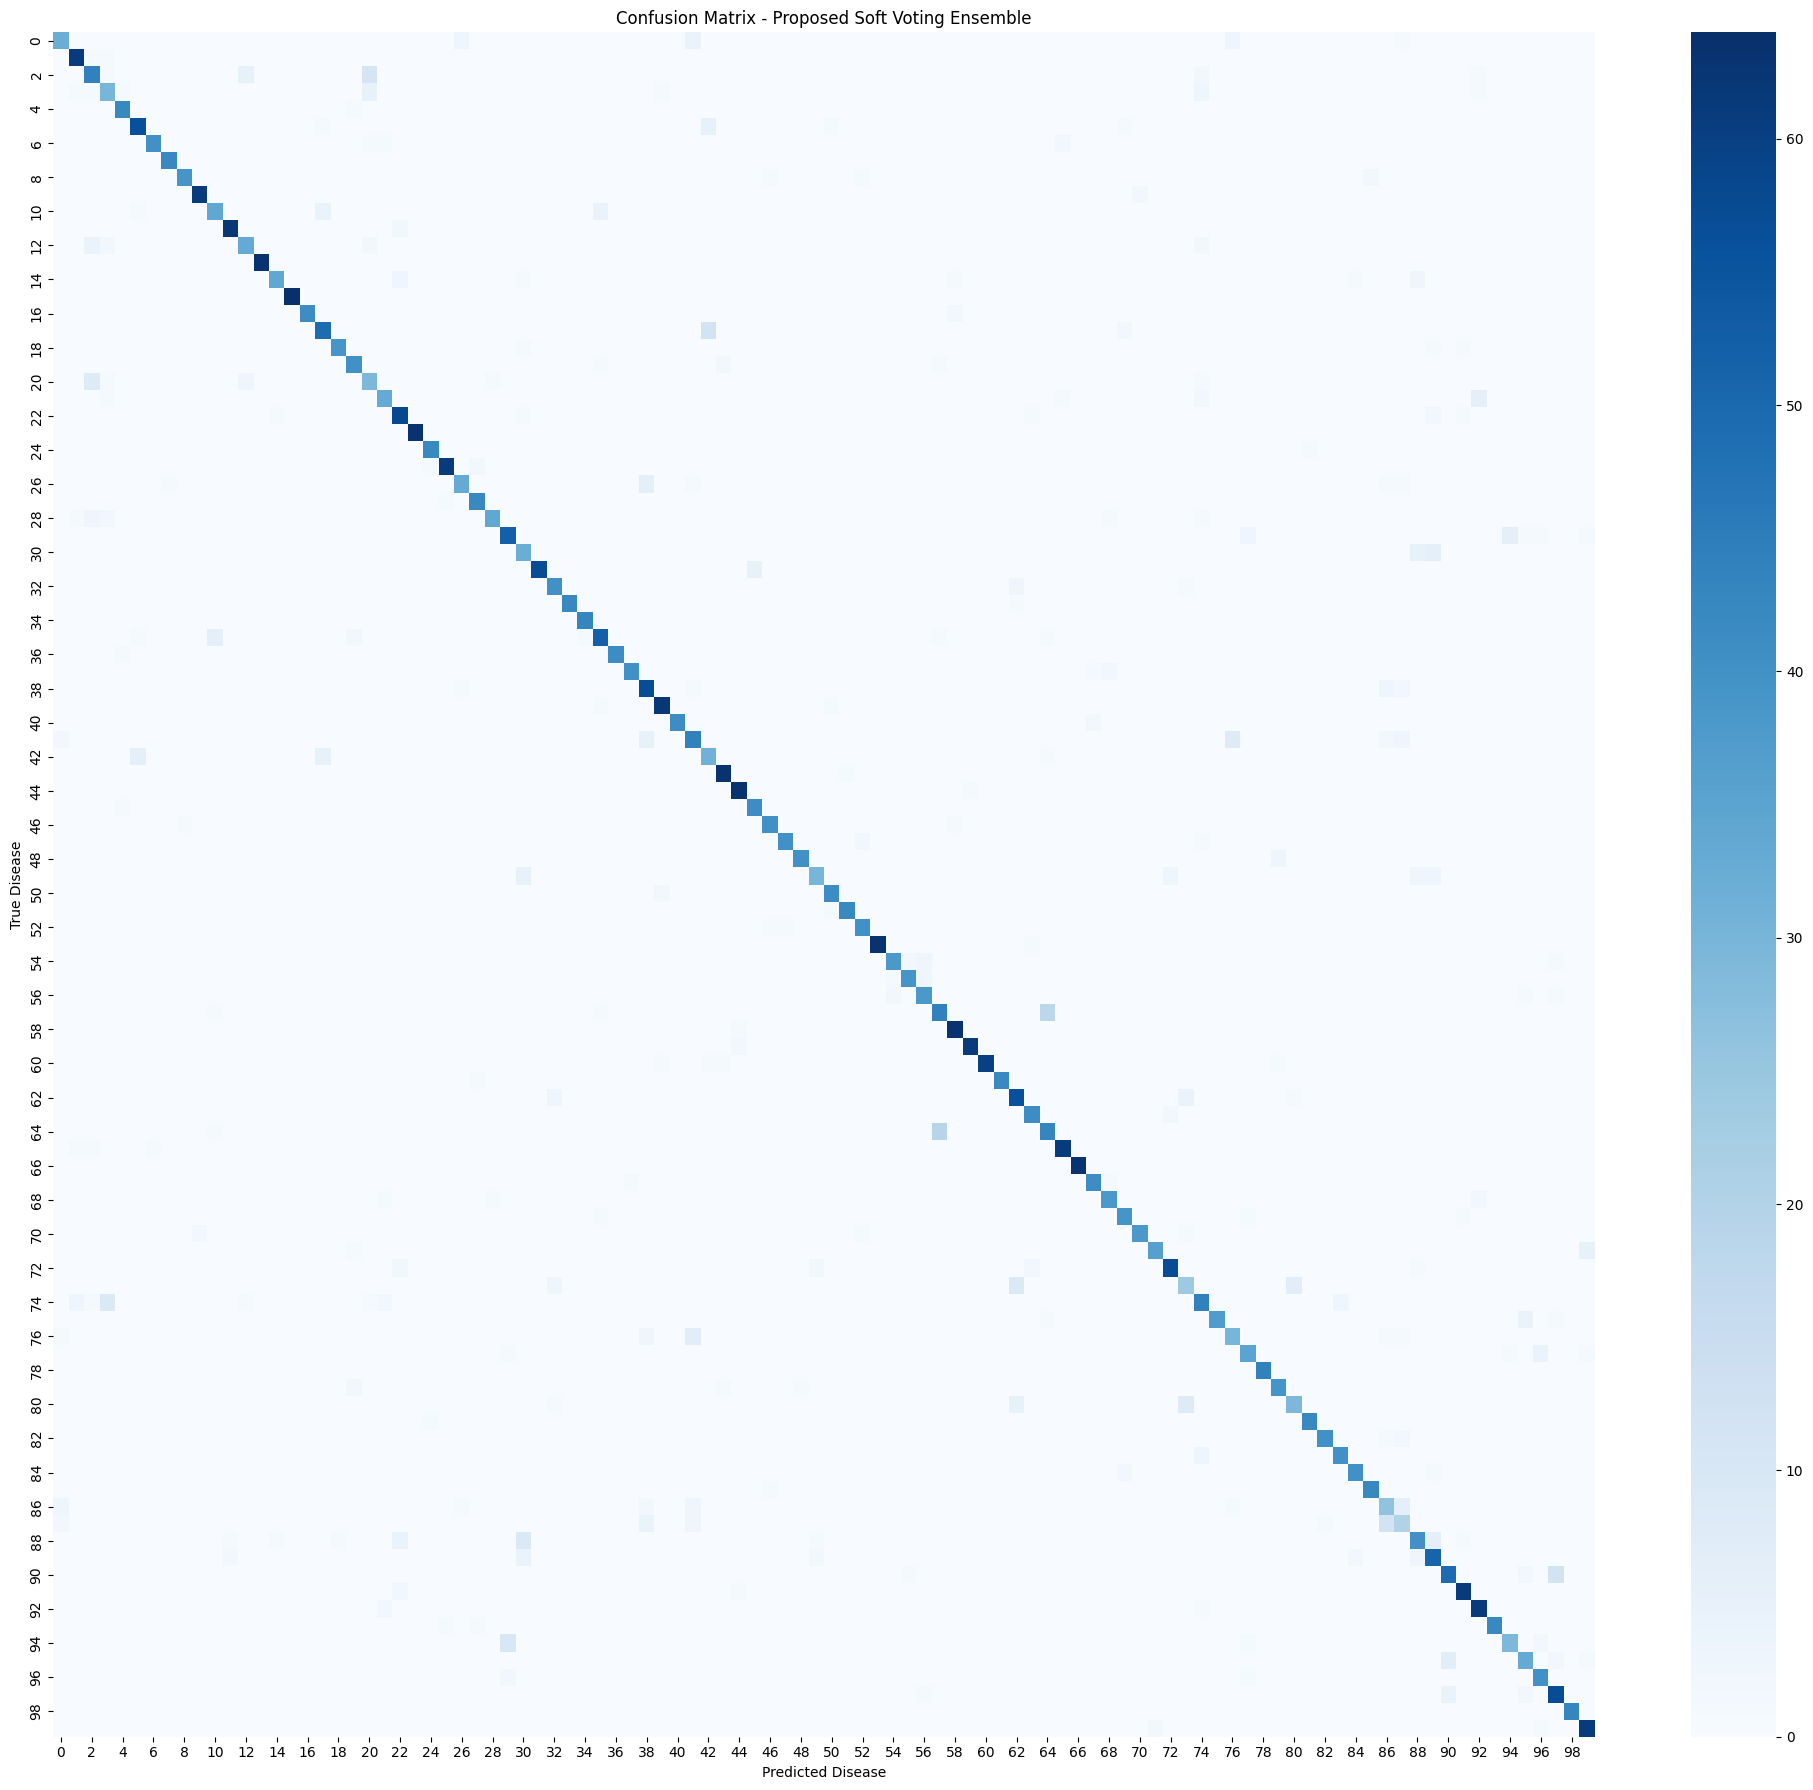

In [ ]:
cm = (
    confusion_matrix(
        y_test,
        ensemble_pred
    )
)


plt.figure(
    figsize=(20, 18)
)


sns.heatmap(
    cm,
    cmap="Blues"
)


plt.title(
    "Confusion Matrix - Proposed Soft Voting Ensemble"
)


plt.xlabel(
    "Predicted Disease"
)


plt.ylabel(
    "True Disease"
)


plt.tight_layout()


plt.savefig(
    "confusion_matrix_ensemble.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

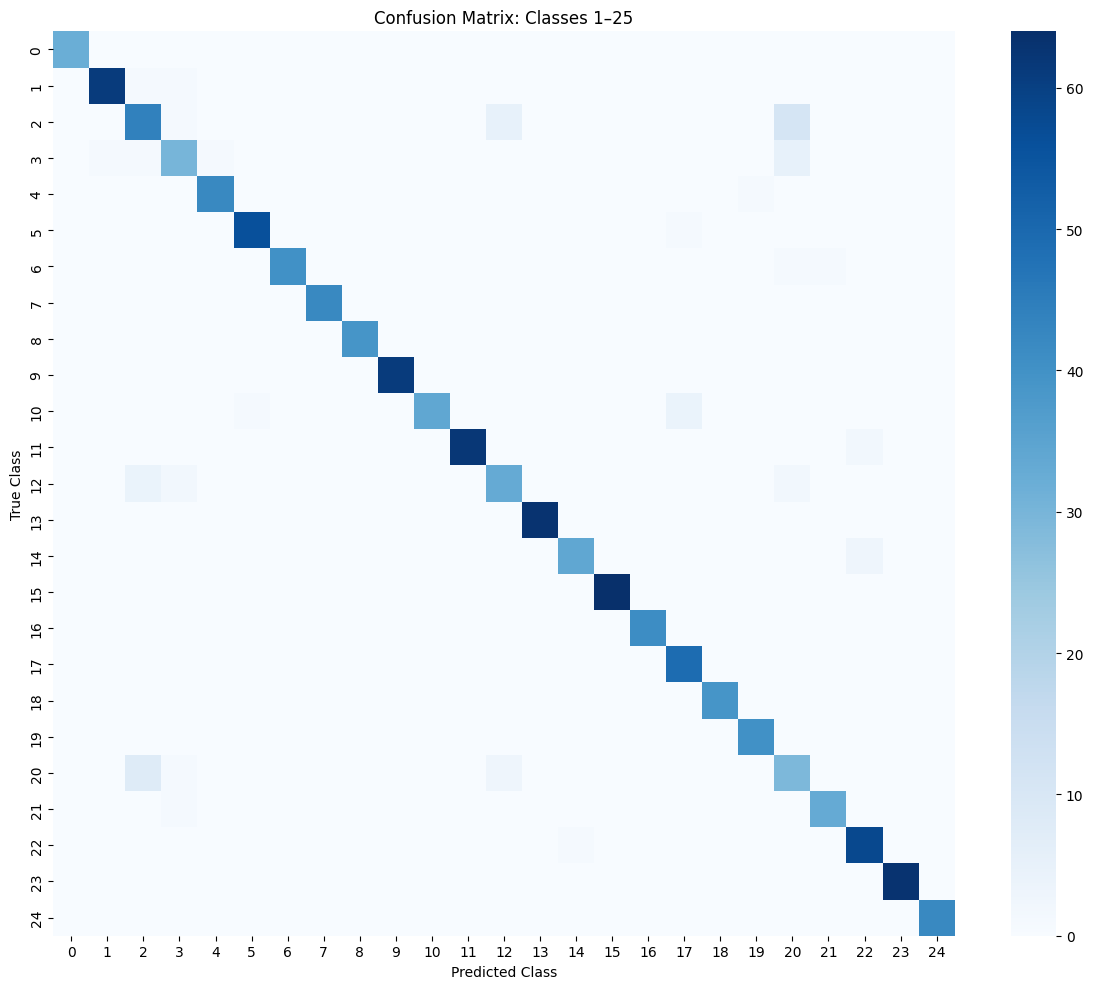

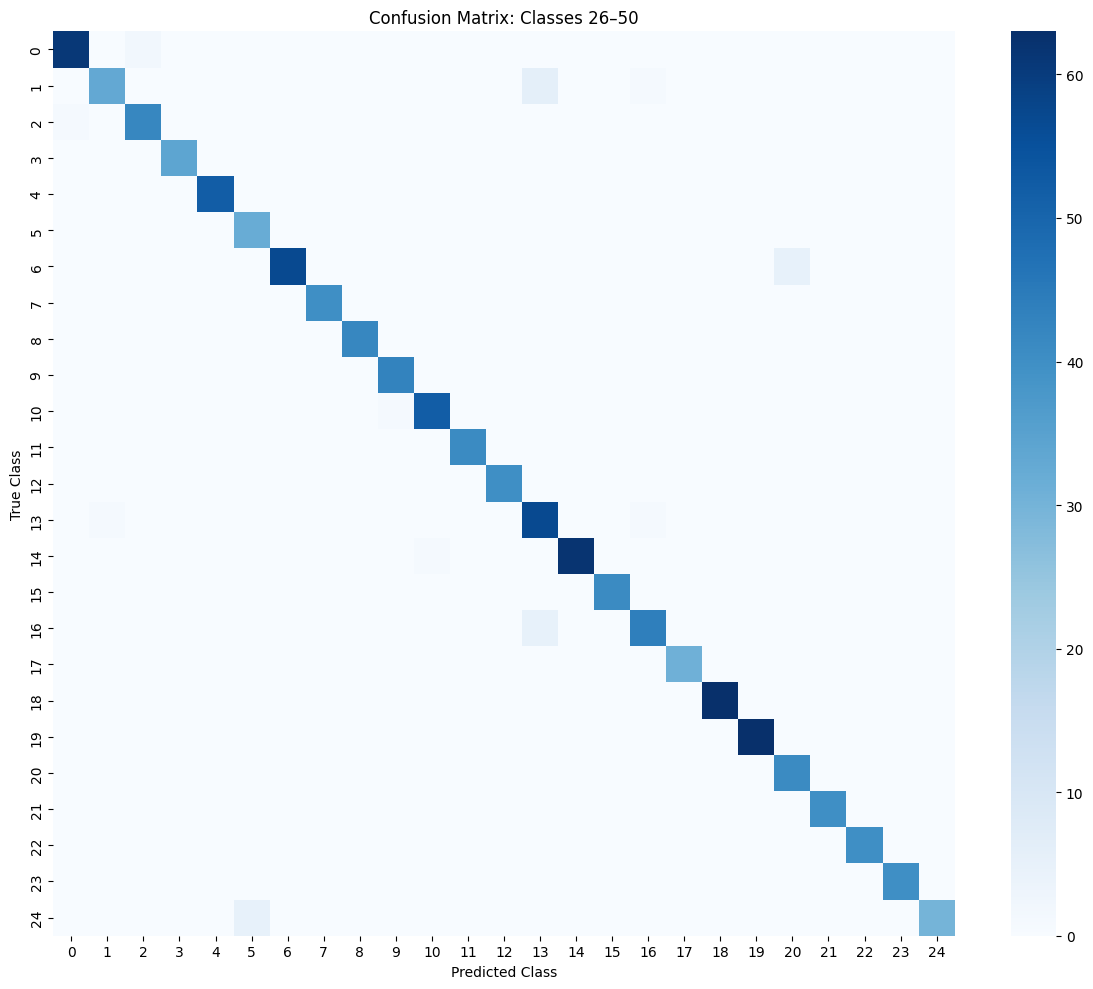

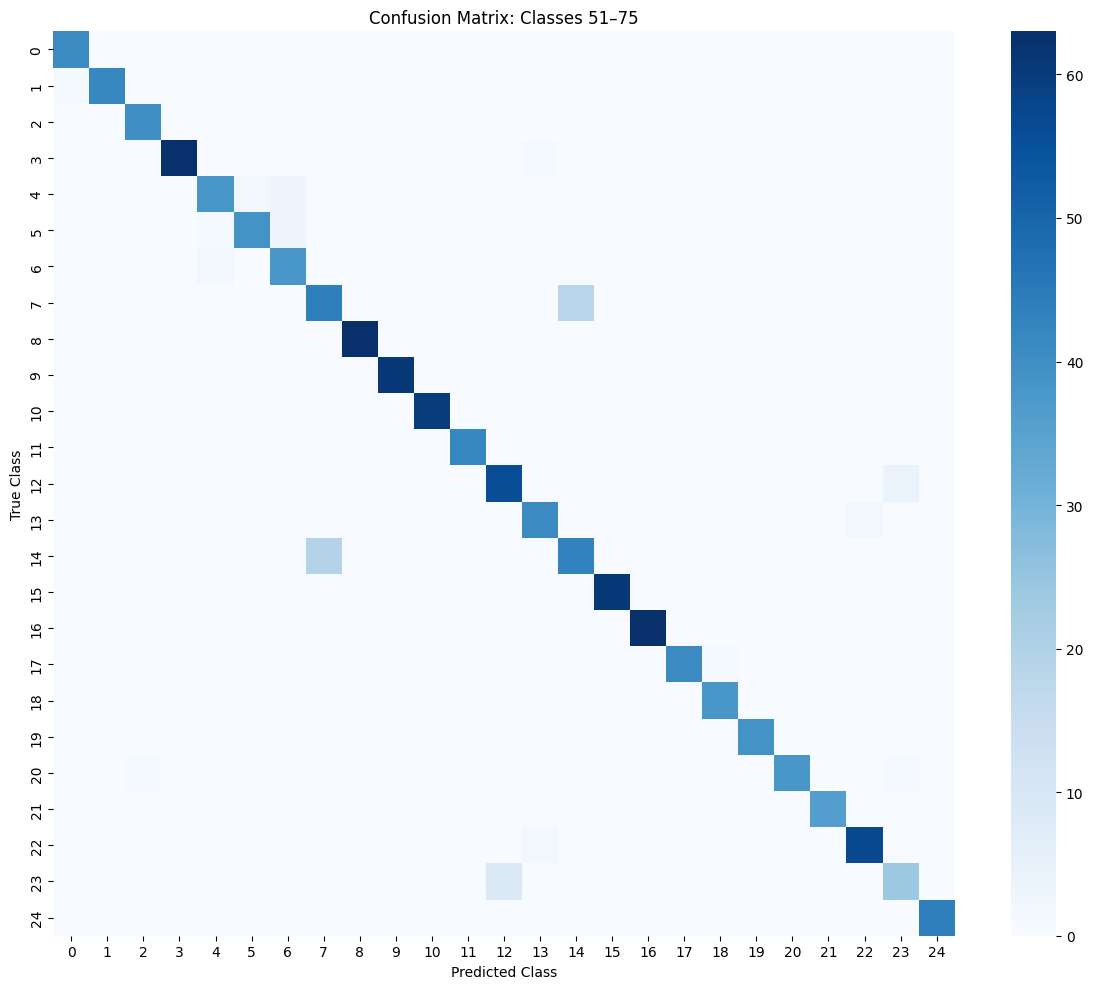

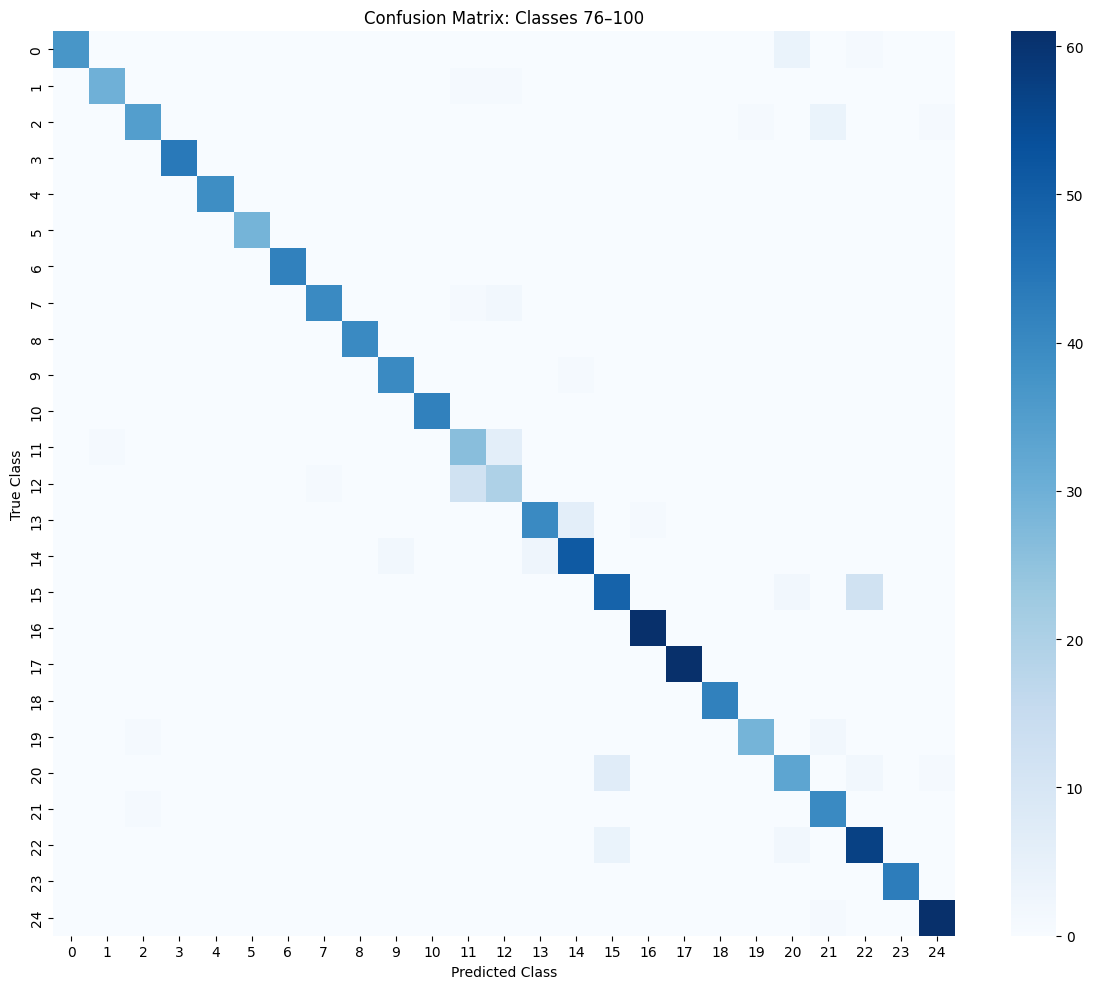

In [ ]:
def plot_confusion_block(
    cm,
    start,
    end,
    title
):

    block = (
        cm[
            start:end,
            start:end
        ]
    )


    plt.figure(
        figsize=(12, 10)
    )


    sns.heatmap(
        block,
        cmap="Blues"
    )


    plt.title(
        title
    )


    plt.xlabel(
        "Predicted Class"
    )


    plt.ylabel(
        "True Class"
    )


    plt.tight_layout()


    plt.savefig(
        f"confusion_matrix_{start+1}_{end}.png",

        dpi=300,

        bbox_inches="tight"
    )


    plt.show()


plot_confusion_block(
    cm,
    0,
    25,
    "Confusion Matrix: Classes 1–25"
)


plot_confusion_block(
    cm,
    25,
    50,
    "Confusion Matrix: Classes 26–50"
)


plot_confusion_block(
    cm,
    50,
    75,
    "Confusion Matrix: Classes 51–75"
)


plot_confusion_block(
    cm,
    75,
    100,
    "Confusion Matrix: Classes 76–100"
)

In [ ]:
mlp_model = (
    experiment_with_ctgan[
        "mlp"
    ]
)


scaler = (
    experiment_with_ctgan[
        "scaler"
    ]
)


X_train_scaled = (
    scaler.transform(
        experiment_with_ctgan[
            "X_train"
        ]
    )
)


X_test_scaled = (
    scaler.transform(
        X_test
    )
)


background_size = min(
    100,
    len(X_train_scaled)
)


explanation_size = min(
    20,
    len(X_test_scaled)
)


background = torch.tensor(
    X_train_scaled[
        :background_size
    ],
    dtype=torch.float32
).to(device)


explain_data = torch.tensor(
    X_test_scaled[
        :explanation_size
    ],
    dtype=torch.float32
).to(device)


try:

    shap_explainer = (
        shap.DeepExplainer(

            mlp_model,

            background
        )
    )


    shap_values = (
        shap_explainer.shap_values(

            explain_data,

            check_additivity=False
        )
    )


    print(
        "SHAP generated successfully."
    )


except Exception as e:

    shap_values = None


    print(
        "SHAP error:"
    )

    print(
        repr(e)
    )

SHAP generated successfully.


In [ ]:
# ============================================================
# CORRECTED SHAP FEATURE IMPORTANCE
# ============================================================

if shap_values is not None:

    # --------------------------------------------------------
    # Convert SHAP output safely
    # --------------------------------------------------------

    if isinstance(shap_values, list):

        # Older SHAP versions:
        # list[class] -> (samples, features)

        shap_array = np.stack(
            shap_values,
            axis=-1
        )

    else:

        shap_array = np.asarray(
            shap_values
        )


    print(
        "SHAP shape:",
        shap_array.shape
    )


    # --------------------------------------------------------
    # Calculate mean absolute SHAP
    # --------------------------------------------------------

    if shap_array.ndim == 3:

        # Expected:
        # (samples, features, classes)

        mean_abs_shap = np.mean(
            np.abs(
                shap_array
            ),
            axis=(0, 2)
        )


    elif shap_array.ndim == 2:

        # (samples, features)

        mean_abs_shap = np.mean(
            np.abs(
                shap_array
            ),
            axis=0
        )


    else:

        raise ValueError(
            f"Unexpected SHAP shape: "
            f"{shap_array.shape}"
        )


    # --------------------------------------------------------
    # Safety check
    # --------------------------------------------------------

    if len(mean_abs_shap) != len(
        feature_columns
    ):

        raise ValueError(
            "Number of SHAP feature values "
            f"({len(mean_abs_shap)}) does not "
            "match number of features "
            f"({len(feature_columns)})."
        )


    # --------------------------------------------------------
    # Create feature-importance table
    # --------------------------------------------------------

    shap_importance = pd.DataFrame({

        "Feature":
            feature_columns,

        "Mean Absolute SHAP":
            mean_abs_shap
    })


    # --------------------------------------------------------
    # Sort by importance
    # --------------------------------------------------------

    shap_importance = (
        shap_importance
        .sort_values(
            "Mean Absolute SHAP",
            ascending=False
        )
        .reset_index(
            drop=True
        )
    )


    # --------------------------------------------------------
    # Display top 20 features
    # --------------------------------------------------------

    print(
        "Top SHAP features:"
    )

    display(
        shap_importance.head(20)
    )


else:

    print(
        "SHAP values are not available."
    )

    shap_importance = pd.DataFrame(
        columns=[
            "Feature",
            "Mean Absolute SHAP"
        ]
    )

SHAP shape: (20, 229, 100)
Top SHAP features:


,Feature,Mean Absolute SHAP
0,abnormal involuntary movements,0.046545
1,coryza,0.031757
2,headache,0.031725
3,vomiting,0.028990
4,pulling at ears,0.027825
5,toothache,0.027599
6,sharp abdominal pain,0.026741
7,paresthesia,0.026035
8,ear pain,0.025699
9,seizures,0.025656


In [ ]:
xgb_model = (
    experiment_with_ctgan[
        "xgb"
    ]
)


lime_explainer = (
    LimeTabularExplainer(

        training_data=
            np.asarray(
                experiment_with_ctgan[
                    "X_train"
                ]
            ),

        feature_names=
            feature_columns,

        class_names=
            list(
                class_names
            ),

        mode=
            "classification",

        discretize_continuous=
            False,

        random_state=
            RANDOM_STATE
    )
)


sample_index = 0


lime_explanation = (
    lime_explainer
    .explain_instance(

        X_test
        .iloc[
            sample_index
        ]
        .values,

        xgb_model
        .predict_proba,

        num_features=10
    )
)


print(
    "Actual disease:"
)


print(
    class_names[
        y_test[
            sample_index
        ]
    ]
)


print(
    "\nLIME explanation:"
)


for (
    feature,
    weight
) in (
    lime_explanation
    .as_list()
):

    print(
        f"{feature}: "
        f"{weight:.6f}"
    )


lime_explanation.save_to_file(
    "lime_explanation.html"
)

Actual disease:
spinal stenosis

LIME explanation:
cough: 0.000237
sharp abdominal pain: -0.000059
hip pain: -0.000036
arm pain: -0.000035
problems with movement: -0.000017
paresthesia: -0.000013
leg pain: -0.000010
loss of sensation: 0.000010
low back pain: 0.000009
neck pain: 0.000003


In [ ]:
xai_table = pd.DataFrame({

    "Module": [
        "SHAP",
        "LIME"
    ],


    "Explanation Type": [

        "Global explanation",

        "Local explanation"
    ],


    "Purpose": [

        "Identify important symptoms/features",

        "Explain an individual prediction"
    ]
})


display(
    xai_table
)

,Module,Explanation Type,Purpose
0,SHAP,Global explanation,Identify important symptoms/features
1,LIME,Local explanation,Explain an individual prediction


In [ ]:
# ============================================================
# BASELINE / MODEL COMPARISON USING YOUR ACTUAL RESULTS
# ============================================================

# Results WITH CTGAN
mlp_result = results_with_ctgan[
    results_with_ctgan["Model"] == "MLP + ResNet"
].iloc[0]

xgb_result = results_with_ctgan[
    results_with_ctgan["Model"] == "XGBoost"
].iloc[0]

rf_result = results_with_ctgan[
    results_with_ctgan["Model"] == "Random Forest"
].iloc[0]

ensemble_result = results_with_ctgan[
    results_with_ctgan["Model"] == "Soft Voting Ensemble"
].iloc[0]


baseline_table = pd.DataFrame({

    "Method": [
        "MLP + ResNet",
        "XGBoost",
        "Random Forest",
        "Proposed CTGAN + Soft Voting Ensemble"
    ],

    "Accuracy (%)": [
        mlp_result["Accuracy (%)"],
        xgb_result["Accuracy (%)"],
        rf_result["Accuracy (%)"],
        ensemble_result["Accuracy (%)"]
    ],

    "Macro F1-score (%)": [
        mlp_result["Macro F1-score (%)"],
        xgb_result["Macro F1-score (%)"],
        rf_result["Macro F1-score (%)"],
        ensemble_result["Macro F1-score (%)"]
    ],

    "Top-3 Accuracy (%)": [
        mlp_result["Top-3 Accuracy (%)"],
        xgb_result["Top-3 Accuracy (%)"],
        rf_result["Top-3 Accuracy (%)"],
        ensemble_result["Top-3 Accuracy (%)"]
    ],

    "Reference": [
        "Implemented baseline",
        "Implemented baseline",
        "Implemented baseline",
        "Proposed"
    ]
})


display(
    baseline_table.round(4)
)

,Method,Accuracy (%),Macro F1-score (%),Top-3 Accuracy (%),Reference
0,MLP + ResNet,86.4373,86.2251,97.7264,Implemented baseline
1,XGBoost,87.6236,87.5403,98.1613,Implemented baseline
2,Random Forest,87.8806,87.7589,98.3393,Implemented baseline
3,Proposed CTGAN + Soft Voting Ensemble,87.6829,87.6507,98.3986,Proposed


In [ ]:
final_results.to_csv(
    "final_model_results.csv",
    index=False
)


ctgan_ablation.to_csv(
    "CTGAN_ablation.csv",
    index=False
)


per_class_results.to_csv(
    "per_class_performance.csv"
)


minority_results.to_csv(
    "minority_class_performance.csv"
)


baseline_table.to_csv(
    "recent_baseline_comparison.csv",
    index=False
)


if len(shap_importance) > 0:

    shap_importance.to_csv(
        "SHAP_feature_importance.csv",
        index=False
    )


print(
    "CSV files saved successfully."
)

CSV files saved successfully.


In [ ]:
excel_file = (
    "Chair_Revision_Results.xlsx"
)


with pd.ExcelWriter(
    excel_file,
    engine="openpyxl"
) as writer:


    final_results.to_excel(

        writer,

        sheet_name=
            "Final Results",

        index=False
    )


    ctgan_ablation.to_excel(

        writer,

        sheet_name=
            "CTGAN Ablation",

        index=False
    )


    per_class_results.to_excel(

        writer,

        sheet_name=
            "Per Class"
    )


    minority_results.to_excel(

        writer,

        sheet_name=
            "Minority Classes"
    )


    baseline_table.to_excel(

        writer,

        sheet_name=
            "Recent Baselines",

        index=False
    )


    xai_table.to_excel(

        writer,

        sheet_name=
            "XAI",

        index=False
    )


print(
    "Excel created:",
    excel_file
)

Excel created: Chair_Revision_Results.xlsx


In [ ]:
print(
    "=========================================="
)

print(
    "FINAL VALIDATION"
)

print(
    "=========================================="
)


# Test-set size

assert (
    len(X_test)
    ==
    len(y_test)
)


# Prediction size

assert (
    len(ensemble_pred)
    ==
    len(y_test)
)


# Metrics

metric_columns = [

    "Accuracy (%)",

    "Macro F1-score (%)",

    "Top-3 Accuracy (%)"
]


for column in (
    metric_columns
):

    assert (
        final_results[
            column
        ]
        .between(
            0,
            100
        )
        .all()
    )


# Top-3 should not be below
# Top-1 accuracy

assert (
    final_ensemble[
        "Top-3 Accuracy (%)"
    ]
    >=
    final_ensemble[
        "Accuracy (%)"
    ]
)


print(
    "All validation checks passed."
)

FINAL VALIDATION
All validation checks passed.


### Training with Updated Configurations
We will update the training configuration variables, train the CTGAN generator using 50 epochs and 100 batch size, generate the synthetic data, and re-train the downstream classifiers (MLP, XGBoost, Random Forest).

In [ ]:
# Apply new configurations
CTGAN_EPOCHS = 50
CTGAN_BATCH_SIZE = 100
MAX_SYNTHETIC_MULTIPLIER = 0.25

RF_ESTIMATORS = 300
RF_MIN_SAMPLES_LEAF = 2

XGB_LEARNING_RATE = 0.03
XGB_MAX_DEPTH = 6

# Redefine the helper functions to respect the new configurations
def augment_with_ctgan_configured(X_train, y_train, target_count=None, epochs=CTGAN_EPOCHS, batch_size=CTGAN_BATCH_SIZE):
    X_train = X_train.copy().reset_index(drop=True)
    y_train = np.asarray(y_train)
    ctgan_data = X_train.copy()
    ctgan_data['disease_label'] = y_train.astype(str)
    class_counts = pd.Series(y_train).value_counts().sort_index()
    if target_count is None:
        target_count = int(class_counts.median())

    discrete_columns = list(X_train.columns) + ['disease_label']
    ctgan = CTGAN(epochs=epochs, batch_size=batch_size, verbose=True)
    print(f'Training CTGAN for {epochs} epochs with batch size {batch_size}...')
    ctgan.fit(ctgan_data, discrete_columns=discrete_columns)

    X_parts = [X_train.values]
    y_parts = [y_train]

    minority_classes = class_counts[class_counts < target_count].index.tolist()
    for class_id in minority_classes:
        current_count = int(class_counts[class_id])
        required = target_count - current_count

        # Respect max synthetic multiplier constraint
        max_allowed_synthetic = int(current_count * MAX_SYNTHETIC_MULTIPLIER)
        required = min(required, max_allowed_synthetic)

        if required <= 0:
            continue
        try:
            synthetic = ctgan.sample(required, condition_column='disease_label', condition_value=str(class_id))
        except Exception:
            pool = ctgan.sample(max(required * 30, 1000))
            synthetic = pool[pool['disease_label'].astype(str) == str(class_id)].head(required)

        if len(synthetic) == 0:
            continue
        synthetic_X = synthetic[X_train.columns].copy().apply(pd.to_numeric, errors='coerce').fillna(0)
        synthetic_X = synthetic_X.round().clip(0, 1)
        X_parts.append(synthetic_X.values)
        y_parts.append(np.full(len(synthetic_X), class_id, dtype=int))

    X_augmented = pd.DataFrame(np.concatenate(X_parts, axis=0), columns=X_train.columns)
    y_augmented = np.concatenate(y_parts, axis=0)
    return X_augmented, y_augmented, ctgan

def train_xgboost_configured(X_train, y_train):
    model = xgb.XGBClassifier(
        objective='multi:softprob',
        num_class=num_classes,
        eval_metric='mlogloss',
        n_estimators=XGB_ESTIMATORS,
        max_depth=XGB_MAX_DEPTH,
        learning_rate=XGB_LEARNING_RATE,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        tree_method='hist'
    )
    model.fit(X_train, y_train)
    return model

def train_random_forest_configured(X_train, y_train):
    model = RandomForestClassifier(
        n_estimators=RF_ESTIMATORS,
        min_samples_leaf=RF_MIN_SAMPLES_LEAF,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
    model.fit(X_train, y_train)
    return model

def train_configured_experiment():
    print('Executing setup with custom configured CTGAN...')
    X_train, y_train, ctgan_model = augment_with_ctgan_configured(X_train_real, y_train_real, target_count=None, epochs=CTGAN_EPOCHS, batch_size=CTGAN_BATCH_SIZE)
    print('Training MLP + ResNet...')
    mlp_model, scaler = train_mlp_resnet(X_train, y_train)
    print('Training Configured XGBoost...')
    xgb_model = train_xgboost_configured(X_train, y_train)
    print('Training Configured Random Forest...')
    rf_model = train_random_forest_configured(X_train, y_train)
    return {'X_train': X_train, 'y_train': y_train, 'mlp': mlp_model, 'scaler': scaler, 'xgb': xgb_model, 'rf': rf_model, 'ctgan': ctgan_model}

# Run the updated experiment pipeline
configured_experiment = train_configured_experiment()
configured_predictions = predict_models(configured_experiment)
configured_results = calculate_metrics(y_test, configured_predictions)

print('\n--- CONFIGURED CTGAN RESULTS ---')
display(configured_results.round(4))

Executing setup with custom configured CTGAN...


NameError: name 'CTGAN' is not defined

In [ ]:
print(
    "\n"
    +
    "=" * 60
)

print(
    "FINAL NUMBERS FOR RESEARCH PAPER"
)

print(
    "=" * 60
)


print(
    f"Accuracy       : "
    f"{final_ensemble['Accuracy (%)']:.4f}%"
)


print(
    f"Macro F1-score : "
    f"{final_ensemble['Macro F1-score (%)']:.4f}%"
)


print(
    f"Top-3 Accuracy : "
    f"{final_ensemble['Top-3 Accuracy (%)']:.4f}%"
)


print(
    "=" * 60
)


print(
    "\nCTGAN ABLATION:"
)


display(
    ctgan_ablation.round(4)
)


FINAL NUMBERS FOR RESEARCH PAPER
Accuracy       : 87.6829%
Macro F1-score : 87.6507%
Top-3 Accuracy : 98.3986%

CTGAN ABLATION:


,Configuration,Accuracy (%),Macro F1-score (%),Top-3 Accuracy (%)
0,Without CTGAN,87.7817,87.7252,98.3393
1,With CTGAN,87.6829,87.6507,98.3986


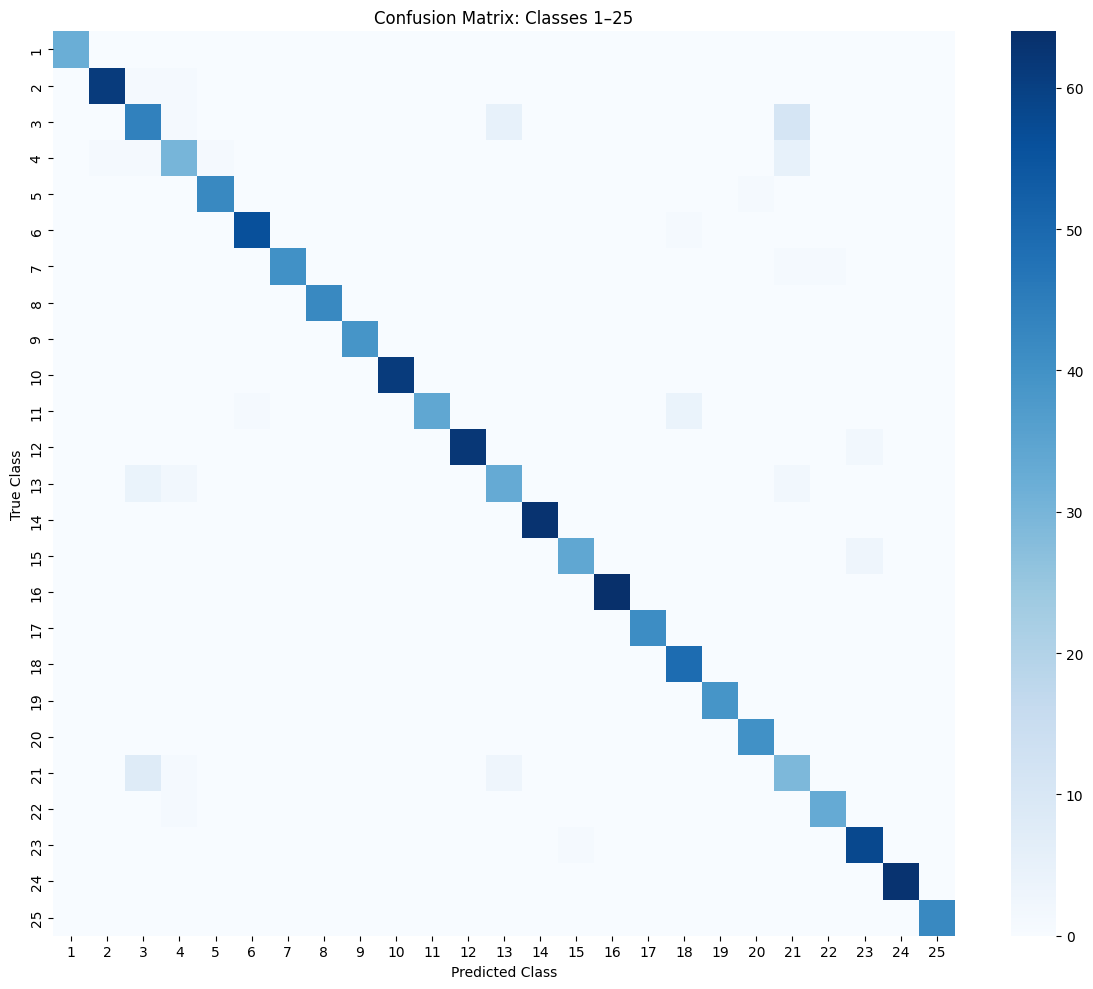

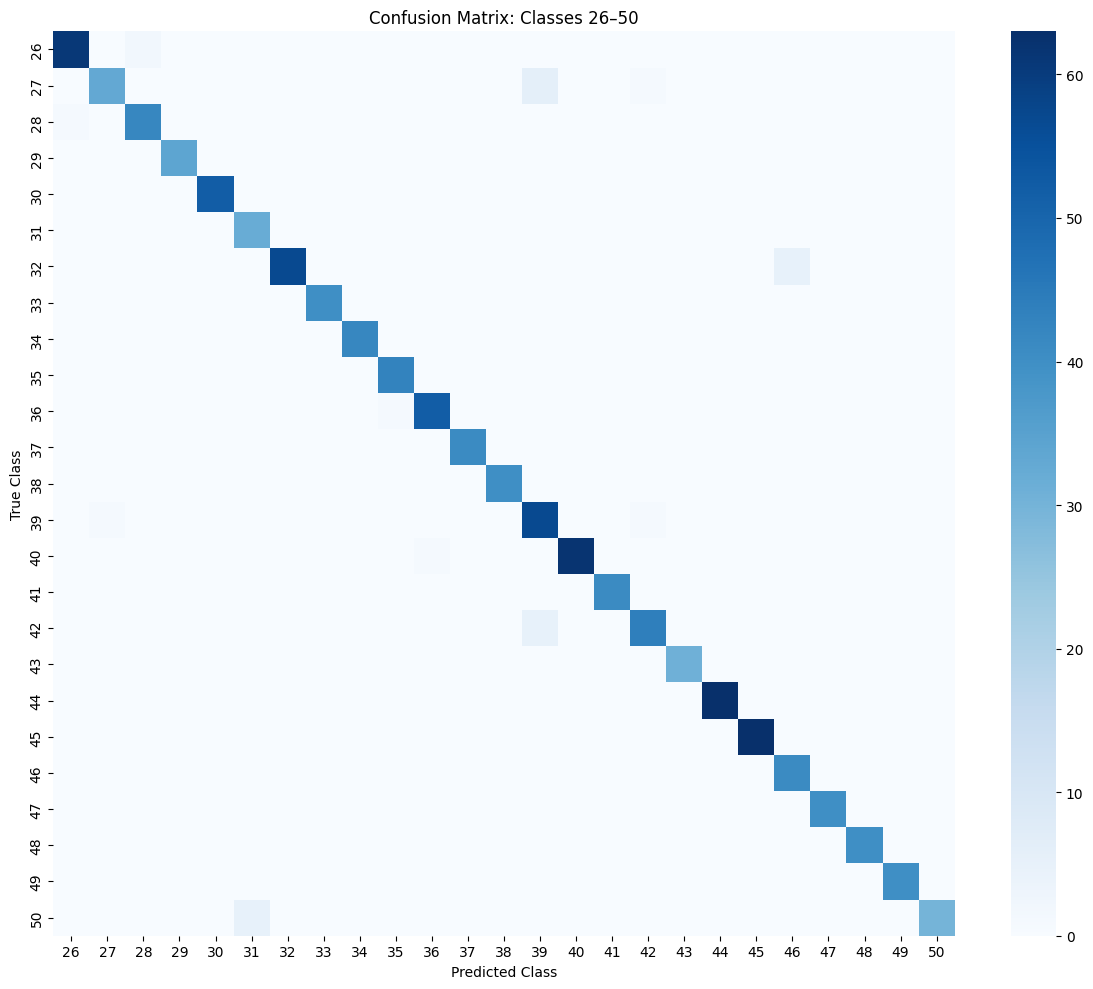

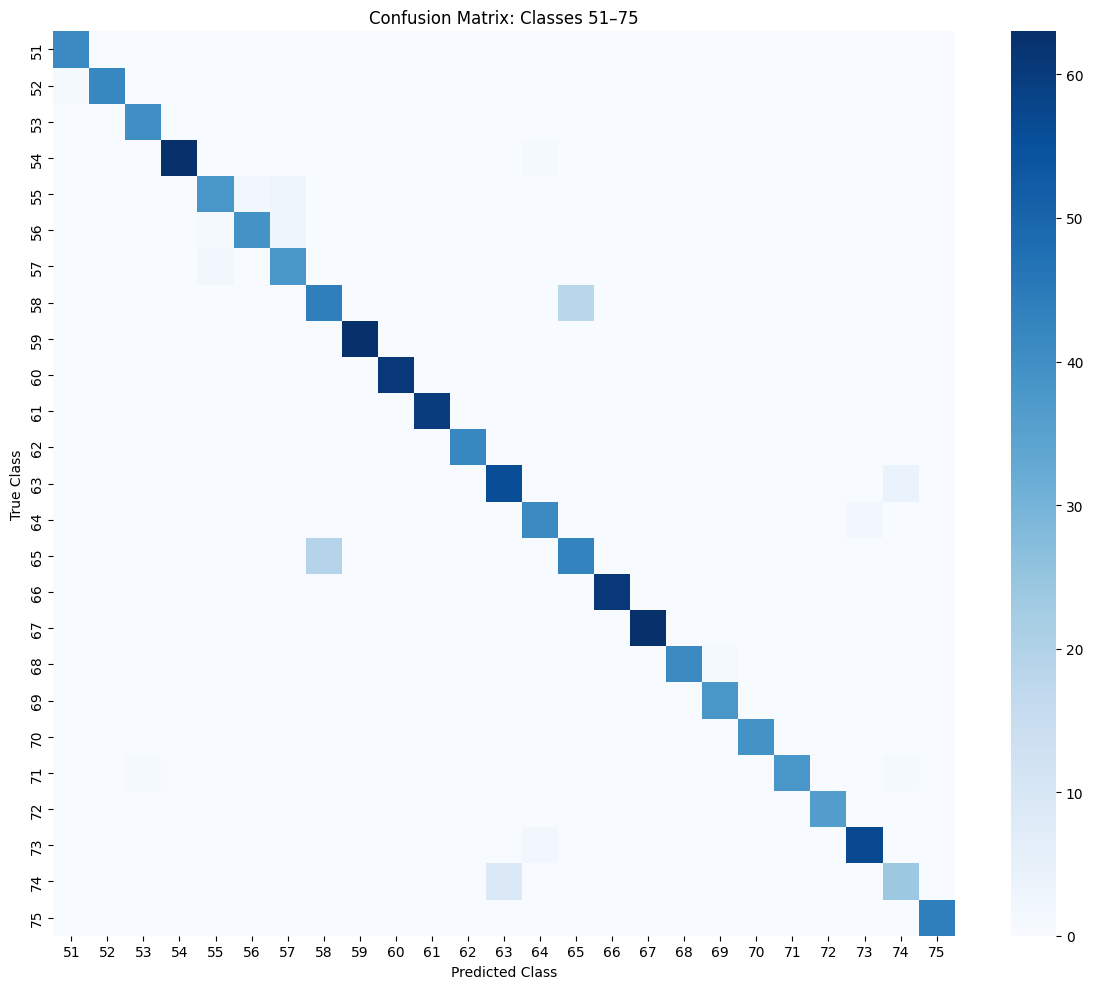

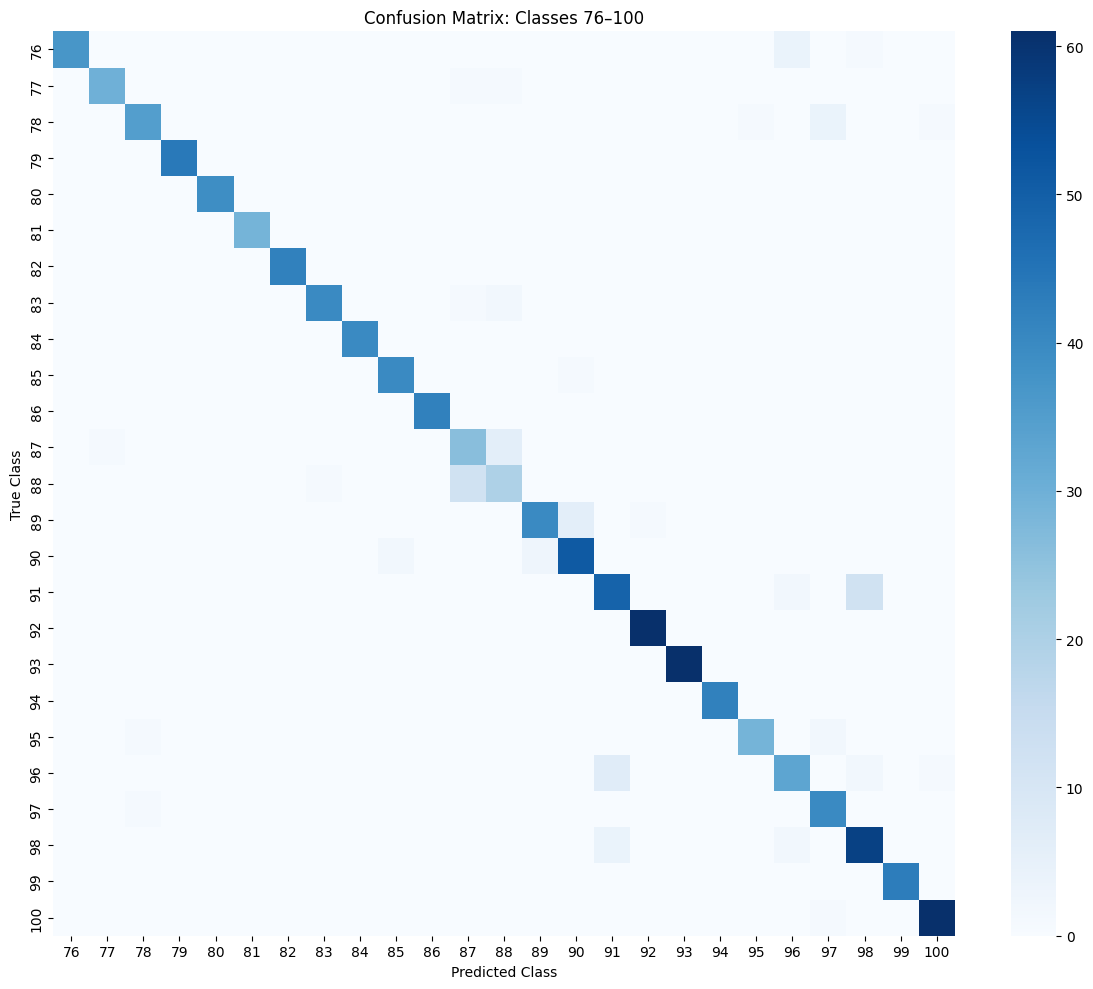

In [ ]:
def plot_confusion_block(cm, start, end, title):

    block = cm[start:end, start:end]

    labels = np.arange(start + 1, end + 1)

    plt.figure(figsize=(12, 10))

    sns.heatmap(
        block,
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels
    )

    plt.title(title)

    plt.xlabel("Predicted Class")
    plt.ylabel("True Class")

    plt.tight_layout()

    plt.savefig(
        f"confusion_matrix_{start+1}_{end}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# Classes 1–25
plot_confusion_block(
    cm,
    0,
    25,
    "Confusion Matrix: Classes 1–25"
)

# Classes 26–50
plot_confusion_block(
    cm,
    25,
    50,
    "Confusion Matrix: Classes 26–50"
)

# Classes 51–75
plot_confusion_block(
    cm,
    50,
    75,
    "Confusion Matrix: Classes 51–75"
)

# Classes 76–100
plot_confusion_block(
    cm,
    75,
    100,
    "Confusion Matrix: Classes 76–100"
)

In [ ]:
print("""
XAI ABLATION INTERPRETATION

SHAP and LIME are post-hoc explainability methods and therefore
do not directly modify the predictive model. Consequently, the
predictive metrics remain unchanged. Their contribution is evaluated
through the additional interpretability they provide.

SHAP provides global feature-importance information, while LIME
provides local explanations for individual predictions. Using both
provides complementary global and local interpretability.
""")


XAI ABLATION INTERPRETATION

SHAP and LIME are post-hoc explainability methods and therefore
do not directly modify the predictive model. Consequently, the
predictive metrics remain unchanged. Their contribution is evaluated
through the additional interpretability they provide.

SHAP provides global feature-importance information, while LIME
provides local explanations for individual predictions. Using both
provides complementary global and local interpretability.



In [ ]:
# ============================================================
# CREATE XAI ABLATION TABLE
# ============================================================

xai_ablation = pd.DataFrame({

    "Configuration": [
        "Ensemble without XAI",
        "Ensemble + SHAP",
        "Ensemble + LIME",
        "Ensemble + SHAP + LIME"
    ],

    "Accuracy (%)": [
        final_ensemble["Accuracy (%)"],
        final_ensemble["Accuracy (%)"],
        final_ensemble["Accuracy (%)"],
        final_ensemble["Accuracy (%)"]
    ],

    "Macro F1-score (%)": [
        final_ensemble["Macro F1-score (%)"],
        final_ensemble["Macro F1-score (%)"],
        final_ensemble["Macro F1-score (%)"],
        final_ensemble["Macro F1-score (%)"]
    ],

    "Top-3 Accuracy (%)": [
        final_ensemble["Top-3 Accuracy (%)"],
        final_ensemble["Top-3 Accuracy (%)"],
        final_ensemble["Top-3 Accuracy (%)"],
        final_ensemble["Top-3 Accuracy (%)"]
    ],

    "Interpretability": [
        "No post-hoc explanation",
        "Global feature importance",
        "Local prediction explanation",
        "Global + local explanation"
    ]
})

display(xai_ablation.round(4))

,Configuration,Accuracy (%),Macro F1-score (%),Top-3 Accuracy (%),Interpretability
0,Ensemble without XAI,87.6829,87.6507,98.3986,No post-hoc explanation
1,Ensemble + SHAP,87.6829,87.6507,98.3986,Global feature importance
2,Ensemble + LIME,87.6829,87.6507,98.3986,Local prediction explanation
3,Ensemble + SHAP + LIME,87.6829,87.6507,98.3986,Global + local explanation


In [ ]:
with pd.ExcelWriter(
    "Chair_Revision_Results.xlsx",
    engine="openpyxl"
) as writer:

    final_results.to_excel(
        writer,
        sheet_name="Final Results",
        index=False
    )

    ctgan_ablation.to_excel(
        writer,
        sheet_name="CTGAN Ablation",
        index=False
    )

    per_class_results.to_excel(
        writer,
        sheet_name="Per Class"
    )

    minority_results.to_excel(
        writer,
        sheet_name="Minority Classes"
    )

    baseline_table.to_excel(
        writer,
        sheet_name="Recent Baselines",
        index=False
    )

    xai_table.to_excel(
        writer,
        sheet_name="XAI",
        index=False
    )

    # Chair-required XAI ablation
    xai_ablation.to_excel(
        writer,
        sheet_name="XAI Ablation",
        index=False
    )

print("Excel file created successfully.")

Excel file created successfully.


In [ ]:
import shap
import matplotlib.pyplot as plt
import numpy as np

# Safely retrieve X_test and xgb_model from previous cells
try:
    X_shap = X_test.copy()
    feature_names = (
        X_shap.columns.tolist()
        if hasattr(X_shap, 'columns')
        else [f'Feature_{i}' for i in range(X_shap.shape[1])]
    )

    explainer = shap.TreeExplainer(xgb_model)
    shap_values = explainer.shap_values(X_shap)

    # For multiclass, combine SHAP values across classes
    if isinstance(shap_values, list):
        shap_values_global = np.mean(
            np.abs(np.stack(shap_values, axis=0)),
            axis=0
        )
    else:
        shap_values_global = shap_values

    plt.figure(figsize=(10, 7))
    shap.summary_plot(
        shap_values_global,
        X_shap,
        feature_names=feature_names,
        max_display=15,
        plot_type='dot',
        show=False
    )
    plt.title('Global SHAP Summary Plot')
    plt.tight_layout()
    plt.savefig(
        'Fig_6_SHAP_Global.png',
        dpi=600,
        bbox_inches='tight'
    )
    plt.show()
except NameError as e:
    print(f'Dependency Error: {e}. Please make sure to run the preprocessing and model training cells first!')

Dependency Error: name 'X_test' is not defined. Please make sure to run the preprocessing and model training cells first!


Computing SHAP values...


<Figure size 1000x700 with 0 Axes>

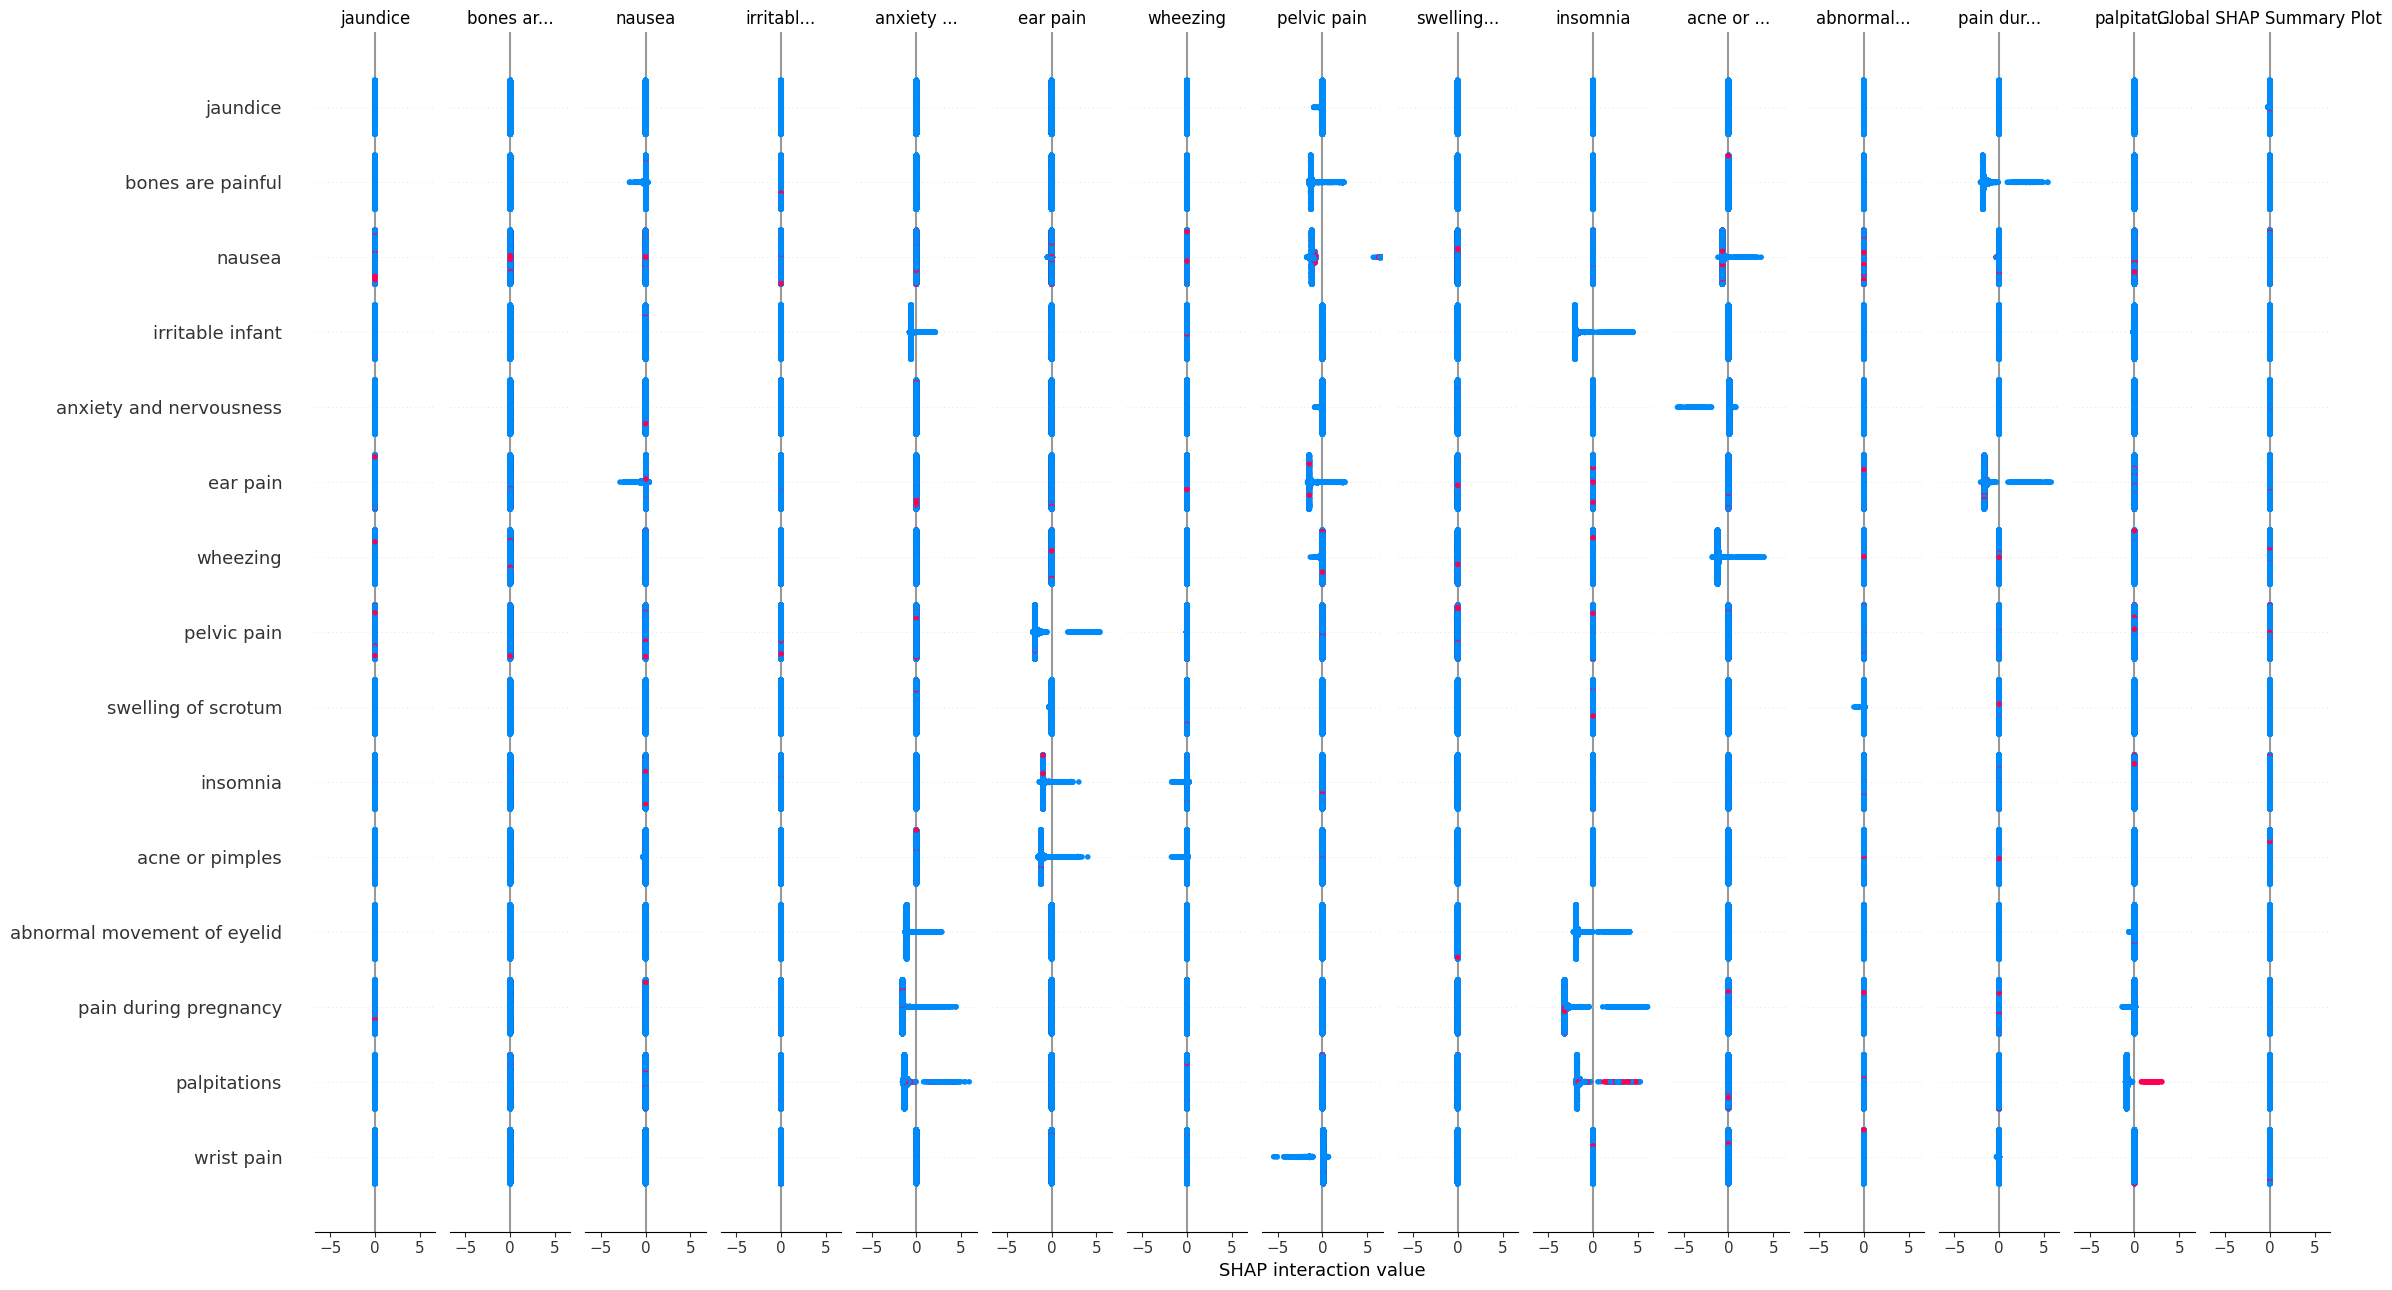

Fig_6_SHAP_Global.png created successfully!


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import xgboost as xgb
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import VarianceThreshold

# 1. Load Data
df_raw = pd.read_csv('/content/Disease_dataset_reduced_50k.csv')
df_raw = df_raw.drop_duplicates().fillna(0)

# 2. Extract top 100 classes
TARGET_COLUMN = 'diseases'
disease_counts = df_raw[TARGET_COLUMN].value_counts()
top_diseases = disease_counts.nlargest(100).index
df_top = df_raw[df_raw[TARGET_COLUMN].isin(top_diseases)].reset_index(drop=True)

feature_columns_original = [c for c in df_top.columns if c != TARGET_COLUMN]
X_original = df_top[feature_columns_original].apply(pd.to_numeric, errors='coerce').fillna(0)
y_text = df_top[TARGET_COLUMN].astype(str)

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_text)

# 3. Variance Threshold
variance_selector = VarianceThreshold(threshold=0.0)
X_selected = variance_selector.fit_transform(X_original)
support_mask = variance_selector.get_support()
feature_columns = [feature_columns_original[i] for i in range(len(feature_columns_original)) if support_mask[i]]
X = pd.DataFrame(X_selected, columns=feature_columns).astype(float)

# 4. Split
X_train_real, X_test, y_train_real, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
X_test = X_test.reset_index(drop=True)

# 5. Fit XGBoost Model using original hyperparameters
xgb_model = xgb.XGBClassifier(
    objective='multi:softprob',
    num_class=100,
    eval_metric='mlogloss',
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    tree_method='hist'
)
xgb_model.fit(X_train_real, y_train_real)

# 6. Compute SHAP & Plot
print('Computing SHAP values...')
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test)

if isinstance(shap_values, list):
    shap_values_global = np.mean(np.abs(np.stack(shap_values, axis=0)), axis=0)
else:
    shap_values_global = shap_values

plt.figure(figsize=(10, 7))
shap.summary_plot(
    shap_values_global,
    X_test,
    feature_names=X_test.columns.tolist(),
    max_display=15,
    plot_type='dot',
    show=False
)
plt.title('Global SHAP Summary Plot')
plt.tight_layout()
plt.savefig('Fig_6_SHAP_Global.png', dpi=600, bbox_inches='tight')
plt.show()
print('Fig_6_SHAP_Global.png created successfully!')